# Right Count, Wrong Reasons — CVPR 2027 Kaggle rerun
## Complete review-response experiment notebook · 12-hour session budget

**Run order:** Kaggle → Settings → **GPU T4 ×2**, **Internet On** → **Save Version → Save & Run All**. Keep the notebook private during review. The default run downloads the original datasets; adding them as inputs is optional. Run the cells in order. No old result, pretrained fine-tuned checkpoint, manually drawn curve, or manuscript number is reused.

This is a **new, post-review protocol**, not a retroactive preregistration. All numerical claims in the current paper must be checked against its outputs. Training uses only the official VisDrone training split, partitioned into training/internal validation. The old official validation split is **selection-disjoint for these new checkpoints but historically inspected**. Test-dev, when labeled data are available, is an additional evaluation; confirm its exposure history before calling it independent. Highway source-video separation remains unverified without a source map.

### Included in this one notebook
- Three fixed-seed YOLOv8n all-vehicle training runs; a separate car-only training control; highway training; matched inference; exploratory YOLOv8s/m and RT-DETR inference.
- Fixed-weight size × occlusion standardization; fixed sparse/dense membership; image-cluster bootstrap; paired setting and pre/post comparisons; seed spread.
- Exploratory equivalence sensitivity at ±1/2/3/5 percentage points (no post-hoc claim that a margin was preregistered), class composition, per-class GT recall, local-neighbor analysis, categorical-occlusion clustered logistic models, alternate strata/minimum counts, truncation sensitivity, synthetic validation.
- Per-image FP/FN and within/across-image cancellation decomposition; GAME(0–3); uniform-relocation spatial null; actual prediction caches and complete settings.
- ByteTrack only, exact video metadata, raw per-frame detection counts, fixed line, 12 operating points, optional real manual annotations; no tracker fallback.
- Saved CSVs, generated LaTeX tables, diagnostic PDF/PNG plots, provenance hashes, checkpoints, an explicit completeness report, and a portable results ZIP. Final paper figure design is deferred.

**Limits:** This notebook cannot guarantee Kaggle uptime, all workloads finishing in 12 hours, a novel result, a non-significant result, or CVPR acceptance. It never changes epochs/thresholds/seed count to make results look complete. A missing or interrupted stage is labeled **INCOMPLETE**. The three seeds are not three independent detector families; the single car-only run does not measure training-seed variability for that control. The second-family check is pretrained inference, not a matched multi-seed fine-tuning replication.


### Cell 01 — Start the 12-hour timer and install dependencies
Expected: pinned Ultralytics installation completes. Existing Kaggle PyTorch/CUDA are retained. The timer includes installation and downloads; it does not extend Kaggle's own session limit.

In [1]:
import os, sys, time, subprocess
from pathlib import Path
SESSION_START = globals().get('SESSION_START', time.time())
TOTAL_BUDGET_HOURS = 12.0
SESSION_DEADLINE = SESSION_START + TOTAL_BUDGET_HOURS * 3600
assert TOTAL_BUDGET_HOURS == 12.0
for key in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS']:
    os.environ[key] = '1'
os.environ['WANDB_DISABLED'] = 'true'
os.environ['WANDB_MODE'] = 'disabled'
os.environ['YOLO_AUTOINSTALL'] = 'false'
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
               'ultralytics==8.3.230', 'statsmodels==0.14.5', 'lap>=0.5.12,<0.6',
               'Jinja2>=3.1,<4', 'PyYAML>=6,<7', 'Pillow>=10'], check=True)
print('✓ Dependencies installed. Total session budget: 12 hours, including setup.')


✓ Dependencies installed. Total session budget: 12 hours, including setup.


### Cell 02 — Frozen rerun settings
Defaults are ready to run. **Do not edit after inspecting evaluation outputs.** To change a scientific setting, use a new `experiment_name` and disclose that change. The 8-hour training allocation is inside the **12-hour total**, leaving time for inference and export; it is not a reduced session timer. Jobs can finish earlier without waiting out the clock.

`resume_source` is optional: an exact previous output directory or its results ZIP attached under `/kaggle/input`. Only this notebook's matching protocol is accepted. A partial run resumes from the optimizer-bearing recovery checkpoint. Completed runs and image prediction caches are reused by identity, never by a loose `best.pt` glob.

For verified source grouping, `source_group_csv` must have `image_id,source_video` (IDs are listed in the manifests). Partial mappings cannot establish source independence. Optional manual frame annotations need `frame,manual_vehicles`. Leave annotations empty if they do not exist; no ground truth is invented.

In [2]:
import json, shutil, zipfile, hashlib
BASE = Path('/kaggle/working')
if not BASE.is_dir():
    raise RuntimeError('This deliverable targets Kaggle. Open it in a Kaggle notebook.')
os.chdir(BASE)
CONFIG = {
    'experiment_name': 'RCWR_CVPR2027_review_r1',
    'mode': 'FULL',                 # FULL or REPORT_ONLY (no training/inference in REPORT_ONLY)
    'resume_source': None,          # exact /kaggle/input/... directory or *_RESULTS.zip
    'split_seed': 2027,
    'seeds': [0, 1, 2],
    'vd_epochs': 35,
    'highway_epochs': 100,
    'train_imgsz': 960,
    'eval_imgsz': 960,
    'primary_tau': 0.25,
    'nms': 0.7,
    'max_det': 1000,
    'thresholds': [0.10, 0.25, 0.40, 0.50, 0.60, 0.70],
    'bootstrap_reps': 2000,
    'bootstrap_seed': 2027,
    'null_reps': 200,
    'car_only_replication': True,
    'test_dev': True,
    'rtdetr': True,
    'mechanism_sizes': [640, 960, 1280, 1600],
    'mechanism_ft_sizes': [960, 1280],
    'mechanism_nms': [0.5, 0.7, 0.9],
    'video_thresholds': [0.25, 0.40, 0.55, 0.70],
    'video_sizes': [480, 640, 960],
    'minimum_track_observations': 15,
    'training_stage_hours': 8.0,
    'export_reserve_minutes': 10,
    'highway_root': None,
    'visdrone_roots': {},           # optional {'train': '...','val': '...','test-dev': '...'}
    'video_path': None,
    'source_group_csv': None,
    'manual_frame_csv': None,
    'manual_crossings': None,
    'total_budget_hours': 12.0,
}
ROOT = BASE / CONFIG['experiment_name']
ROOT.mkdir(parents=True, exist_ok=True)
SOURCES = ROOT / 'sources'
SOURCES.mkdir(exist_ok=True)
CONFIG.update(root=str(ROOT), session_start=SESSION_START)
if CONFIG['resume_source']:
    src = Path(CONFIG['resume_source'])
    if not src.exists(): raise FileNotFoundError(src)
    if src.is_file():
        with zipfile.ZipFile(src) as z:
            for entry in z.infolist():
                p = (ROOT / entry.filename).resolve()
                if not p.is_relative_to(ROOT.resolve()): raise ValueError('Unsafe archive path')
                if entry.filename.startswith('sources/'): continue
                z.extract(entry, ROOT)
    else:
        for item in src.iterdir():
            if item.name in ['data','downloads','sources']: continue
            dst = ROOT / item.name
            if item.is_dir(): shutil.copytree(item, dst, dirs_exist_ok=True)
            else: shutil.copy2(item, dst)
    print('Restored requested previous outputs; protocol identity will be checked.')
MODULE_SOURCES = {}
print('✓ Configuration ready:', ROOT)


✓ Configuration ready: /kaggle/working/RCWR_CVPR2027_review_r1


### Cell 03 — Embedded module: `rcwr_core.py`
Complete readable source is embedded below. This cell writes the implementation; execution begins in Cell 11.

In [3]:
MODULE_SOURCES['rcwr_core.py'] = r'''"""CPU-only estimands; no detector imports and no paper numbers hard-coded."""
import hashlib, json, os, time
from pathlib import Path
import numpy as np
import pandas as pd

VERSION = 'rcwr-kaggle-2027-r1'
VEHICLES = {4:'car', 5:'van', 6:'truck', 9:'bus'}

def digest(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(2**20),b''): h.update(b)
    return h.hexdigest()

def atomic_json(path, value):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_suffix(path.suffix+'.tmp')
    tmp.write_text(json.dumps(value,indent=2,default=lambda x:x.item() if hasattr(x,'item') else str(x),allow_nan=False))
    os.replace(tmp,path)

def iou(a,b):
    a=np.asarray(a).reshape(-1,4); b=np.asarray(b).reshape(-1,4)
    wh=np.maximum(0,np.minimum(a[:,None,2:],b[None,:,2:])-np.maximum(a[:,None,:2],b[None,:,:2]))
    inter=wh.prod(2); aa=np.maximum(0,a[:,2:]-a[:,:2]).prod(1); bb=np.maximum(0,b[:,2:]-b[:,:2]).prod(1)
    return inter/np.maximum(aa[:,None]+bb[None,:]-inter,1e-12)

def match(gt,pred,score,threshold=.5):
    hit=np.zeros(len(gt),bool); good=np.zeros(len(pred),bool); assignment=np.full(len(pred),-1,int)
    overlap=iou(pred,gt)
    for j in np.argsort(-score,kind='stable'):
        free=np.flatnonzero(~hit)
        if not len(free): break
        k=free[np.argmax(overlap[j,free])]
        if overlap[j,k]>=threshold: hit[k]=True; good[j]=True; assignment[j]=k
    return hit,good,assignment

def inside(boxes,regions):
    if not len(boxes) or not len(regions): return np.zeros(len(boxes),bool)
    c=(boxes[:,:2]+boxes[:,2:])/2
    return ((c[:,None,:]>=regions[None,:,:2])&(c[:,None,:]<=regions[None,:,2:])).all(2).any(1)

def features(boxes):
    size=np.sqrt(np.maximum(0,boxes[:,2:]-boxes[:,:2]).prod(1))
    ctr=(boxes[:,:2]+boxes[:,2:])/2
    d=np.linalg.norm(ctr[:,None]-ctr[None,:],axis=2); np.fill_diagonal(d,np.inf)
    return size,(d<2*size[:,None]).sum(1)

def grid_counts(boxes,w,h,L):
    n=2**L
    if not len(boxes): return np.zeros(n*n,int)
    xy=np.floor(((boxes[:,:2]+boxes[:,2:])/2)/[w,h]*n).astype(int).clip(0,n-1)
    return np.bincount(xy[:,1]*n+xy[:,0],minlength=n*n)

def make_tables(records,predictions,tau=.25):
    images=[]; objects=[]; classes=[]
    assert len(records)==len(predictions)
    for r,p in zip(records,predictions):
        b=np.asarray(p['boxes'],float).reshape(-1,4); sc=np.asarray(p['scores'],float)
        keep=(sc>=tau)&~inside(b,np.asarray(r['ignore'],float).reshape(-1,4)); b=b[keep]; sc=sc[keep]
        gt=np.asarray(r['boxes'],float).reshape(-1,4); hit,good,assignment=match(gt,b,sc)
        n=len(gt); tp=int(hit.sum()); fp=len(b)-tp; fn=n-tp
        row=dict(image=r['id'],gt_n=n,scene_n=r.get('scene_n',n),pred_n=len(b),tp=tp,fp=fp,fn=fn,error=len(b)-n,
                 hidden_within=2*min(fp,fn),width=r['width'],height=r['height'])
        for L in range(4): row[f'game{L}']=int(abs(grid_counts(b,r['width'],r['height'],L)-grid_counts(gt,r['width'],r['height'],L)).sum())
        assert row['game0']==abs(row['error']) and fp-fn==row['error']
        assert tp+fn==n and tp+fp==len(b)
        assert all(row[f'game{L+1}']>=row[f'game{L}'] for L in range(3))
        images.append(row); sz,nb=features(gt)
        for k in range(n): objects.append(dict(image=r['id'],object_id=k,gt_n=r.get('scene_n',n),size=float(sz[k]),neighbors=int(nb[k]),
            occ=int(r['occ'][k]),trunc=int(r['trunc'][k]),category=int(r['category'][k]),hit=int(hit[k])))
        for cat in sorted(set(r['category'])):
            mask=np.array(r['category'])==cat
            classes.append(dict(image=r['id'],category=cat,n=int(mask.sum()),tp=int(hit[mask].sum())))
    return pd.DataFrame(images),pd.DataFrame(objects,columns=['image','object_id','gt_n','size','neighbors','occ','trunc','category','hit']),pd.DataFrame(classes)

def count_summary(di):
    n=di.gt_n.sum(); pr=di.pred_n.sum(); tp=di.tp.sum(); fn=di.fn.sum(); fp=di.fp.sum(); e=di.error.to_numpy()
    within=int(di.hidden_within.sum()); across=int(abs(e).sum()-abs(e.sum()))
    assert int(fp+fn)==int(abs(e.sum()))+within+across
    near=abs(e)<=1; burden=(di.fp>=2)&(di.fn>=2)
    out=dict(n_images=len(di),gt_total=int(n),pred_total=int(pr),tp=int(tp),fp=int(fp),fn=int(fn),
      recall=float(tp/n) if n else np.nan,precision=float(tp/pr) if pr else np.nan,
      mae=float(abs(e).mean()),rmse=float(np.sqrt((e**2).mean())),nmae=float(abs(e).sum()/n) if n else np.nan,
      bias_pct=float(100*e.sum()/n) if n else np.nan,miss_pct_gt=float(100*fn/n) if n else np.nan,fp_pct_gt=float(100*fp/n) if n else np.nan,
      hidden_within_total=within,hidden_across_total=across,near_correct_images=int(near.sum()),near_correct_both_ge2=int((near&burden).sum()),
      near_correct_both_ge2_fraction=float((near&burden).sum()/near.sum()) if near.sum() else np.nan)
    for L in range(4): out[f'GAME{L}']=float(di[f'game{L}'].mean())
    out['GAME3_over_GAME0']=out['GAME3']/out['GAME0'] if out['GAME0'] else np.nan
    return out

def group_plan(di,B=2000,seed=2027):
    """Fixed disjoint count-tertile membership; independent image resampling within each group."""
    counts=di.get('scene_n',di.gt_n).to_numpy(); eligible=counts>0
    ql,qh=np.quantile(counts[eligible],[1/3,2/3])
    if ql>=qh: raise ValueError('Count tertiles overlap: cannot define disjoint sparse/dense groups.')
    lo=np.flatnonzero(eligible&(counts<=ql)); hi=np.flatnonzero(eligible&(counts>=qh))
    rng=np.random.default_rng(seed)
    return dict(ids=di.image.tolist(),low=lo,high=hi,ql=float(ql),qh=float(qh),B=B,seed=seed,
        wl=rng.multinomial(len(lo),np.full(len(lo),1/len(lo)),size=B).astype(float),
        wh=rng.multinomial(len(hi),np.full(len(hi),1/len(hi)),size=B).astype(float))

def stat_ci(point,boot):
    good=np.isfinite(boot); valid=int(good.sum()); out=dict(estimate_pp=float(point*100),valid_bootstraps=valid,total_bootstraps=len(boot))
    if valid<len(boot)*.99 or valid<100:
        out.update(ci95_low_pp=np.nan,ci95_high_pp=np.nan,ci_valid=False)
    else:
        ci=np.quantile(boot[good],[.025,.975])*100
        out.update(ci95_low_pp=float(ci[0]),ci95_high_pp=float(ci[1]),ci_valid=True)
    return out

def raw_effect(di,do,plan):
    g=do.groupby('image').hit.agg(['sum','count']).reindex(plan['ids'],fill_value=0)
    H=g['sum'].to_numpy(float); N=g['count'].to_numpy(float); lo=plan['low']; hi=plan['high']
    def ratio(h,n): return np.divide(h,n,out=np.full(np.shape(h),np.nan),where=n>0)
    point=ratio(H[lo].sum(),N[lo].sum())-ratio(H[hi].sum(),N[hi].sum())
    boot=ratio(plan['wl']@H[lo],plan['wl']@N[lo])-ratio(plan['wh']@H[hi],plan['wh']@N[hi])
    return stat_ci(point,boot),boot

def standardized(di,do,plan,edges=(16,32,64),min_count=20):
    assert di.image.tolist()==plan['ids']
    valid=do[do.occ.isin([0,1,2])].copy(); K=(len(edges)+1)*3
    valid['stratum']=np.digitize(valid['size'],edges,right=False)*3+valid.occ.astype(int)
    ix={s:i for i,s in enumerate(plan['ids'])}; N=np.zeros((len(di),K)); H=N.copy()
    if len(valid):
        for (im,s),v in valid.groupby(['image','stratum']).hit.agg(['sum','count']).iterrows():
            N[ix[im],int(s)]=v['count']; H[ix[im],int(s)]=v['sum']
    lo,hi=plan['low'],plan['high']; nl=N[lo].sum(0); nh=N[hi].sum(0)
    retained=(nl>=min_count)&(nh>=min_count); w=np.zeros(K)
    if retained.any(): w[retained]=(nl+nh)[retained]/(nl+nh)[retained].sum()
    strata=pd.DataFrame(dict(stratum=np.arange(K),size_band=np.arange(K)//3,occlusion=np.arange(K)%3,
        n_sparse=nl,n_dense=nh,tp_sparse=H[lo].sum(0),tp_dense=H[hi].sum(0),retained=retained,weight=w))
    strata['recall_sparse']=strata.tp_sparse/strata.n_sparse.replace(0,np.nan)
    strata['recall_dense']=strata.tp_dense/strata.n_dense.replace(0,np.nan)
    if not retained.any():
        boot=np.full(plan['B'],np.nan); point=np.nan
    else:
        m=retained
        point=np.sum(w[m]*(H[lo].sum(0)[m]/nl[m]-H[hi].sum(0)[m]/nh[m]))
        nlb=plan['wl']@N[lo][:,m]; nhb=plan['wh']@N[hi][:,m]
        with np.errstate(divide='ignore',invalid='ignore'):
            boot=np.sum(w[m]*((plan['wl']@H[lo][:,m])/nlb-(plan['wh']@H[hi][:,m])/nhb),axis=1)
        # Do not silently drop empty strata or recalculate weights in bootstrap replicates.
        boot[(nlb==0).any(1)|(nhb==0).any(1)]=np.nan
    out=stat_ci(point,boot); out.update(strata_retained=int(retained.sum()),strata_total=K,
        excluded_sparse=int(nl[~retained].sum()),excluded_dense=int(nh[~retained].sum()),
        total_sparse=int(nl.sum()),total_dense=int(nh.sum()),min_count=min_count,size_edges='|'.join(map(str,edges)))
    return out,boot,strata

def equivalence(point_pp,boot_pp,margins=(1.,2.,3.,5.)):
    """Exploratory centered-bootstrap TOST, with dual 90% basic bootstrap interval.
    Margins are a post-review sensitivity analysis, NOT independently justified SESOIs.
    """
    good=boot_pp[np.isfinite(boot_pp)]; rows=[]
    valid=len(good)>=max(100,.99*len(boot_pp)) and np.isfinite(point_pp)
    for delta in margins:
        if valid:
            error=good-point_pp
            low=point_pp-np.quantile(error,.95); high=point_pp-np.quantile(error,.05)
            pl=(1+(error>=point_pp+delta).sum())/(len(error)+1)
            pu=(1+(error<=point_pp-delta).sum())/(len(error)+1)
            eq=bool(pl<.05 and pu<.05)
        else: low=high=pl=pu=np.nan; eq=False
        rows.append(dict(margin_pp=delta,basic90_low_pp=low,basic90_high_pp=high,p_lower=pl,p_upper=pu,
                         equivalent=eq,inference_valid=valid,interpretation='exploratory margin sensitivity; not a causal null'))
    return rows

def null_relocation(records,predictions,tau=.25,repetitions=200,seed=2027):
    rng=np.random.default_rng(seed); observed=[]; sums=np.zeros(repetitions); denominator=0
    for r,p in zip(records,predictions):
        b=np.array(p['boxes'],float).reshape(-1,4); sc=np.array(p['scores']); ig=np.array(r['ignore'],float).reshape(-1,4)
        b=b[(sc>=tau)&~inside(b,ig)]; gt=np.array(r['boxes'],float).reshape(-1,4); n=len(b)
        w,h=r['width'],r['height']; g=grid_counts(gt,w,h,3)
        denominator+=abs(n-len(gt)); observed.append(abs(grid_counts(b,w,h,3)-g).sum())
        for k in range(repetitions):
            centers=[]; needed=n; attempts=0
            while needed and attempts<100:
                xy=rng.random((max(needed*2,10),2))*[w,h]; fake=np.c_[xy,xy]
                xy=xy[~inside(fake,ig)][:needed]; centers.extend(xy); needed-=len(xy); attempts+=1
            if needed: raise ValueError('Unable to sample non-ignored image support for null.')
            xy=np.array(centers).reshape(-1,2); cells=np.floor(xy/[w,h]*8).astype(int).clip(0,7)
            pred=np.bincount(cells[:,1]*8+cells[:,0],minlength=64)
            sums[k]+=abs(pred-g).sum()
    obs=float(np.mean(observed)); sims=sums/len(records); d=denominator/len(records)
    return dict(observed_GAME3=obs,GAME0=d,observed_ratio=obs/d if d else np.nan,
        null_GAME3_mean=float(sims.mean()),null_GAME3_p025=float(np.quantile(sims,.025)),null_GAME3_p975=float(np.quantile(sims,.975)),
        null_ratio_mean=float(sims.mean()/d) if d else np.nan,
        null_lower_tail_mc_p=float((1+(sims<=obs).sum())/(repetitions+1)),
        null_definition='Independent uniform relocation of predicted centers over non-ignored image area; per-image counts fixed. Illustrative spatial null, not a traffic generative model.'),sims

def self_tests():
    g=np.array([[0,0,10,10],[20,20,30,30]],float)
    h,ok,_=match(g,np.array([[0,0,10,10],[0,0,10,10],[40,40,50,50]]),np.array([.9,.8,.7]))
    assert h.tolist()==[True,False] and ok.tolist()==[True,False,False]
    r=dict(id='x',boxes=g.tolist(),ignore=[],occ=[0,0],trunc=[0,0],category=[4,4],width=64,height=64)
    p=dict(boxes=[[0,0,10,10],[40,40,50,50]],scores=[.9,.8])
    di,do,_=make_tables([r],[p]); s=count_summary(di)
    assert s['bias_pct']==0 and s['hidden_within_total']==2 and s['recall']==.5
    images=[]; obs=[]
    # Exactly matched strata within each image; planted 20 pp effect is deterministic.
    for i in range(90):
        n=60 if i<30 else (120 if i<60 else 180); images.append(dict(image=str(i),gt_n=n))
        for j in range(n):
            obs.append(dict(image=str(i),size=12 if j%2 else 48,occ=0,hit=int(j%10<8),category=4,trunc=0,neighbors=j%4))
    di=pd.DataFrame(images); do=pd.DataFrame(obs); plan=group_plan(di,B=300)
    a,b,st=standardized(di,do,plan); assert abs(a['estimate_pp'])<1e-10 and np.isclose(st.weight.sum(),1)
    planted=do.copy(); dense=planted.image.astype(int)>=60
    # In each image, remove one quarter of the previously successful hits.
    for im,idx in planted[dense].groupby('image').groups.items():
        chosen=planted.loc[idx].index[planted.loc[idx,'hit']==1][::4]; planted.loc[chosen,'hit']=0
    a,b,st=standardized(di,planted,plan); assert np.isclose(a['estimate_pp'],20) and a['ci95_low_pp']>0
    eq=equivalence(0.,np.zeros(300)); assert all(q['equivalent'] for q in eq)
    return {'matching':'pass','count_decomposition':'pass','fixed_weight_null':'pass','planted_20pp':'pass','equivalence':'pass'}
'''
(SOURCES / 'rcwr_core.py').write_text(MODULE_SOURCES['rcwr_core.py'], encoding='utf-8')
print('✓ Wrote rcwr_core.py')

✓ Wrote rcwr_core.py


### Cell 04 — Embedded module: `rcwr_data.py`
Complete readable source is embedded below. This cell writes the implementation; execution begins in Cell 11.

In [4]:
MODULE_SOURCES['rcwr_data.py'] = r'''import json, os, shutil, urllib.request, zipfile, time
from pathlib import Path
import numpy as np
import pandas as pd
import yaml
from PIL import Image
from rcwr_core import atomic_json,digest,VEHICLES

SUFFIXES={'.jpg','.jpeg','.png','.bmp'}

def download_extract(url,target,downloads):
    target=Path(target); downloads=Path(downloads); target.mkdir(parents=True,exist_ok=True); downloads.mkdir(parents=True,exist_ok=True)
    archive=downloads/(url.split('/')[-1].split('?')[0]+'.zip' if '?' in url else url.split('/')[-1])
    if not archive.exists():
        error=None
        for attempt in range(3):
            try:
                request=urllib.request.Request(url,headers={'User-Agent':'RCWR-research/1.0'})
                with urllib.request.urlopen(request,timeout=120) as src,open(str(archive)+'.part','wb') as dst: shutil.copyfileobj(src,dst)
                os.replace(str(archive)+'.part',archive); error=None; break
            except Exception as e: error=e; time.sleep(2*(attempt+1))
        if error: raise RuntimeError(f'Download failed: {url}. Attach the extracted dataset with Add Input. {error}')
    with zipfile.ZipFile(archive) as z:
        for item in z.infolist():
            destination=(target/item.filename).resolve()
            if not destination.is_relative_to(target.resolve()): raise ValueError('Unsafe archive path')
        z.extractall(target)
    return target

def locate_vd(base,split):
    base=Path(base)
    if not base.exists(): return None
    exact='VisDrone2019-DET-'+split
    candidates=[base] if base.name==exact else list(base.rglob(exact))
    candidates=[p for p in candidates if (p/'images').is_dir() and (p/'annotations').is_dir()]
    return sorted(candidates)[0] if candidates else None

def obtain_vd(split,root,cfg):
    manual=cfg.get('visdrone_roots',{}).get(split)
    if manual:
        p=Path(manual)
        if not (p/'annotations').is_dir(): raise ValueError(f'Missing raw annotations: {p}')
        return p
    for base in [root/'data',Path('/kaggle/input')]:
        p=locate_vd(base,split)
        if p: return p
    url='https://github.com/ultralytics/assets/releases/download/v0.0.0/VisDrone2019-DET-'+split+'.zip'
    download_extract(url,root/'data',root/'downloads')
    p=locate_vd(root/'data',split)
    if not p: raise RuntimeError(f'{split}: images AND raw annotations required. No test labels will be invented.')
    return p

def parse_visdrone(root,split):
    records=[]
    for p in sorted((root/'images').iterdir()):
        if p.suffix.lower() not in SUFFIXES: continue
        with Image.open(p) as im: w,h=im.size
        ann=root/'annotations'/(p.stem+'.txt')
        if not ann.exists(): raise FileNotFoundError(ann)
        boxes=[]; occ=[]; trunc=[]; category=[]; ignore=[]
        for line in ann.read_text().splitlines():
            if not line.strip(): continue
            q=line.strip().split(',')
            if len(q)<8: raise ValueError(f'Malformed annotation: {ann}')
            x,y,bw,bh,score,cat,tr,oc=map(lambda s:int(float(s)),q[:8])
            b=[max(0,x),max(0,y),min(w,x+bw),min(h,y+bh)]
            if b[2]<=b[0] or b[3]<=b[1]: continue
            if score==0 or cat==0: ignore.append(b)
            elif cat in VEHICLES:
                if oc not in (0,1,2): raise ValueError('Unexpected occlusion category')
                boxes.append(b); occ.append(oc); trunc.append(tr); category.append(cat)
        records.append(dict(id=split+'/'+p.name,path=str(p),annotation=str(ann),boxes=boxes,occ=occ,trunc=trunc,
            category=category,ignore=ignore,width=w,height=h,sha256=digest(p),label_sha256=digest(ann),source_group='unverified'))
    if not records: raise ValueError(f'Empty split: {root}')
    return records

def highway_root(base):
    base=Path(base)
    if not base.exists(): return None
    for p in [base]+sorted(base.rglob('train')):
        p=p.parent if p.name=='train' else p
        if (p/'train'/'images').is_dir() and any((p/s/'images').is_dir() for s in ['valid','val']): return p
    return None

def obtain_highway(root,cfg):
    p=highway_root(cfg.get('highway_root') or '/kaggle/input') or highway_root(root/'data'/'highway')
    if not p:
        download_extract('https://www.kaggle.com/api/v1/datasets/download/farzadnekouei/top-view-vehicle-detection-image-dataset?dataset_version_number=2',root/'data'/'highway',root/'downloads')
        p=highway_root(root/'data'/'highway')
    if not p: raise RuntimeError('Attach farzadnekouei/top-view-vehicle-detection-image-dataset with Add Input.')
    return p

def parse_highway(root,split):
    result=[]
    for p in sorted((root/split/'images').iterdir()):
        if p.suffix.lower() not in SUFFIXES: continue
        with Image.open(p) as im: w,h=im.size
        ann=root/split/'labels'/(p.stem+'.txt'); boxes=[]
        if not ann.exists(): raise FileNotFoundError(f'Explicit empty labels are required: {ann}')
        for line in ann.read_text().splitlines():
            q=line.split()
            if not q: continue
            if len(q)==5:
                xc,yc,bw,bh=map(float,q[1:]); b=[(xc-bw/2)*w,(yc-bh/2)*h,(xc+bw/2)*w,(yc+bh/2)*h]
            elif len(q)>5 and (len(q)-1)%2==0:
                xy=np.array(q[1:],float).reshape(-1,2)*[w,h]; b=[*xy.min(0),*xy.max(0)]
            else: raise ValueError(f'Malformed highway label: {ann}')
            b=[max(0,b[0]),max(0,b[1]),min(w,b[2]),min(h,b[3])]
            if b[2]>b[0] and b[3]>b[1]: boxes.append(b)
        result.append(dict(id='highway_'+split+'/'+p.name,path=str(p),annotation=str(ann),boxes=boxes,occ=[-1]*len(boxes),
            trunc=[-1]*len(boxes),category=[0]*len(boxes),ignore=[],width=w,height=h,sha256=digest(p),label_sha256=digest(ann),source_group='unverified'))
    return result

def split_training(records,protected,cfg,tag,root):
    protected_hashes={r['sha256'] for r in protected}; retained=[]; excluded=[]
    groups={}
    mapping=cfg.get('source_group_csv')
    if mapping:
        df=pd.read_csv(mapping,dtype=str)
        if not {'image_id','source_video'}.issubset(df): raise ValueError('source_group_csv needs image_id,source_video')
        if df.image_id.duplicated().any() or df.source_video.isna().any(): raise ValueError('Invalid source mapping')
        groups=dict(zip(df.image_id,df.source_video))
    protected_groups={groups[r['id']] for r in protected if r['id'] in groups}
    for r in records:
        if r['sha256'] in protected_hashes or (r['id'] in groups and groups[r['id']] in protected_groups): excluded.append(r)
        else: retained.append(r)
    keys={r['id']:groups.get(r['id'],r['sha256']) for r in retained}
    unique=sorted(set(keys.values())); rng=np.random.default_rng(cfg['split_seed']); rng.shuffle(unique)
    cut=max(1,int(round(.1*len(unique)))); val_keys=set(unique[:cut]); train=[]; val=[]
    for r in retained:
        (val if keys[r['id']] in val_keys else train).append(r)
    if not train or not val: raise ValueError('Insufficient training/internal-validation groups')
    rows=[]
    for label,items in [('train',train),('internal_val',val),('excluded_exact_or_known_source_overlap',excluded)]:
        rows.extend(dict(dataset=tag,image_id=r['id'],partition=label,sha256=r['sha256'],source_video=groups.get(r['id'],'unverified')) for r in items)
    pd.DataFrame(rows).to_csv(root/'manifests'/f'{tag}_split.csv',index=False)
    return train,val

def write_yolo(train,val,root,tag):
    # Single vehicle class, preserving original study's training target. GT categories remain in analysis records.
    dest=root/'data'/('yolo_'+tag)
    for split,items in [('train',train),('val',val)]:
        idir=dest/'images'/split; ldir=dest/'labels'/split; idir.mkdir(parents=True,exist_ok=True); ldir.mkdir(parents=True,exist_ok=True)
        for r in items:
            name=r['id'].replace('/','__'); dst=idir/name
            if dst.is_symlink() and not dst.exists(): dst.unlink()
            if not dst.exists(): dst.symlink_to(Path(r['path']).resolve())
            lines=[]
            for x1,y1,x2,y2 in r['boxes']:
                w,h=r['width'],r['height']; lines.append(f'0 {(x1+x2)/2/w:.9f} {(y1+y2)/2/h:.9f} {(x2-x1)/w:.9f} {(y2-y1)/h:.9f}')
            (ldir/(Path(name).stem+'.txt')).write_text('\n'.join(lines)+'\n' if lines else '')
    yp=root/'manifests'/f'{tag}.yaml'
    yp.write_text(yaml.safe_dump(dict(path=str(dest),train='images/train',val='images/val',names={0:'vehicle'})))
    return str(yp)

def near_duplicate_audit(train,val,root):
    def dh(r):
        with Image.open(r['path']) as im: a=np.asarray(im.convert('L').resize((9,8)))
        return (a[:,1:]>a[:,:-1]).reshape(-1)
    a=np.array([dh(r) for r in train]); rows=[]
    for r in val:
        dist=(a!=dh(r)).sum(1)
        for j in np.flatnonzero(dist<=4): rows.append(dict(train_id=train[j]['id'],evaluation_id=r['id'],dhash_distance=int(dist[j]),status='candidate only; requires visual/source verification'))
    pd.DataFrame(rows,columns=['train_id','evaluation_id','dhash_distance','status']).to_csv(root/'manifests'/'highway_near_duplicate_candidates.csv',index=False)

def car_subset(records):
    result=[]
    for r in records:
        r=dict(r); keep=[i for i,c in enumerate(r['category']) if c==4]; r['scene_n']=len(r['boxes'])
        for k in ['boxes','occ','trunc','category']: r[k]=[r[k][i] for i in keep]
        result.append(r)
    return result

def prepare_data(root,cfg):
    (root/'manifests').mkdir(exist_ok=True,parents=True)
    tr=parse_visdrone(obtain_vd('train',root,cfg),'train'); va=parse_visdrone(obtain_vd('val',root,cfg),'val')
    if len(tr)!=6471 or len(va)!=548: raise ValueError(f'Unexpected VisDrone split sizes {len(tr)}/{len(va)}; check input.')
    datasets={'visdrone_val':va}; optional=[]
    if cfg['test_dev']:
        try:
            td=parse_visdrone(obtain_vd('test-dev',root,cfg),'test-dev')
            if len(td)!=1610: raise ValueError(f'Expected 1610 test-dev images, got {len(td)}')
            datasets['visdrone_testdev']=td
        except Exception as e:
            optional.append(dict(stage='testdev_data',status='unavailable',reason=str(e)))
            print('Additional test-dev evaluation unavailable:',e,flush=True)
    protected=sum(datasets.values(),[]); a,b=split_training(tr,protected,cfg,'visdrone',root)
    yamls={'visdrone':write_yolo(a,b,root,'visdrone')}
    if cfg['car_only_replication']:
        yamls['visdrone_car']=write_yolo(car_subset(a),car_subset(b),root,'visdrone_car')
    hroot=obtain_highway(root,cfg); hsplit='valid' if (hroot/'valid').exists() else 'val'
    ht=parse_highway(hroot,'train'); hv=parse_highway(hroot,hsplit); ha,hb=split_training(ht,hv,cfg,'highway',root)
    yamls['highway']=write_yolo(ha,hb,root,'highway'); datasets['highway']=hv
    near_duplicate_audit(ht,hv,root)
    video=cfg.get('video_path'); vids=sorted(hroot.rglob('sample_video.mp4'))
    if not video and vids: video=str(vids[0])
    # Manifest every training, validation and evaluation image and annotation hash.
    manifests=[]
    for name,items in [('visdrone_train_original',tr),('highway_train_original',ht)]+list(datasets.items()):
        for r in items: manifests.append(dict(dataset=name,image_id=r['id'],sha256=r['sha256'],label_sha256=r['label_sha256'],vehicles=len(r['boxes']),width=r['width'],height=r['height']))
    pd.DataFrame(manifests).to_csv(root/'manifests'/'all_images.csv',index=False)
    # Overlap between reported evaluation splits is audited, not silently described as independent.
    overlap=[]
    names=list(datasets)
    for i,x in enumerate(names):
        for y in names[i+1:]:
            common={r['sha256'] for r in datasets[x]}&{r['sha256'] for r in datasets[y]}
            overlap.append(dict(a=x,b=y,shared_exact_image_hashes=len(common)))
    atomic_json(root/'manifests'/'evaluation_overlap.json',overlap)
    atomic_json(root/'manifests'/'dataset_policy.json',dict(visdrone_val='Selection-disjoint in NEW training; historically inspected, not pristine.',
        testdev='Additional benchmark evaluation if available; authors must confirm no earlier exposure. Source independence not established by filenames.',
        highway='Illustrative roadside oblique-view dataset; source-video independence UNVERIFIED unless a complete verified source_group_csv is supplied.',
        training='Single vehicle class. Scored vehicle boxes only; ignored regions are not masked in training. Custom evaluation filters prediction centers in ignored regions; not the official VisDrone AP protocol.',
        truncation='Retained in primary analysis; non-truncated recall sensitivity also exported.',
        class_mapping='COCO {car,bus,truck}; FT all-vehicle class. Primary evaluation is class-agnostic union. Car-only GT recall is a coverage diagnostic, not car-only detection precision or a proof of semantic equivalence.'))
    atomic_json(root/'datasets.json',datasets); atomic_json(root/'data_setup.json',dict(yamls=yamls,video=video,optional=optional))
    return datasets,yamls,video,optional
'''
(SOURCES / 'rcwr_data.py').write_text(MODULE_SOURCES['rcwr_data.py'], encoding='utf-8')
print('✓ Wrote rcwr_data.py')

✓ Wrote rcwr_data.py


### Cell 05 — Embedded module: `rcwr_train.py`
Complete readable source is embedded below. This cell writes the implementation; execution begins in Cell 11.

In [5]:
MODULE_SOURCES['rcwr_train.py'] = r'''import os
os.environ['WANDB_DISABLED']='true'; os.environ['WANDB_MODE']='disabled'; os.environ['YOLO_AUTOINSTALL']='false'
import json, sys, time, traceback, shutil
from pathlib import Path
from rcwr_core import atomic_json,digest

def run(job_path):
    job=json.loads(Path(job_path).read_text()); root=Path(job['root']); out=root/'training'/job['tag']; out.mkdir(parents=True,exist_ok=True)
    from ultralytics import YOLO,settings
    settings.update({'wandb':False,'mlflow':False,'clearml':False,'comet':False,'neptune':False,'dvc':False,'tensorboard':False})
    stop_path=root/'STOP_TRAINING'; requested_stop=[False]
    def deadline(trainer):
        if time.time()>=job['deadline'] or stop_path.exists():
            trainer.stop=True; requested_stop[0]=True
    resume=out/'weights'/'recovery_last.pt'
    def preserve(trainer):
        if Path(trainer.last).exists(): shutil.copy2(trainer.last,resume)
    try:
        model=YOLO(str(resume) if resume.exists() else job['initial_weights'])
        model.add_callback('on_model_save',preserve)
        model.add_callback('on_train_epoch_end',deadline)
        model.add_callback('on_train_batch_end',deadline)
        kwargs=dict(data=job['data'],epochs=job['epochs'],imgsz=job['imgsz'],device=job.get('device',0),batch=job.get('batch',8),workers=2,
            seed=job['seed'],deterministic=True,optimizer='AdamW',lr0=.001,lrf=.01,patience=0,
            project=str(root/'training'),name=job['tag'],exist_ok=True,save=True,save_period=5,
            plots=False,verbose=False,cache=False,amp=True,close_mosaic=10)
        if resume.exists(): kwargs['resume']=True
        model.train(**kwargs)
        epoch=int(model.trainer.epoch)+1
        best=out/'weights'/'best.pt'; complete=epoch>=job['epochs'] and not requested_stop[0]
        atomic_json(out/'status.json',dict(status='complete' if complete else 'partial',epochs_finished=epoch,requested_epochs=job['epochs'],
            checkpoint=str(best) if best.exists() else None,checkpoint_sha256=digest(best) if best.exists() else None,
            seed=job['seed'],selection='internal_val only',completed_at=time.time(),job=job))
    except Exception:
        atomic_json(out/'status.json',dict(status='failed',error=traceback.format_exc(),job=job)); raise

if __name__=='__main__': run(sys.argv[1])
'''
(SOURCES / 'rcwr_train.py').write_text(MODULE_SOURCES['rcwr_train.py'], encoding='utf-8')
print('✓ Wrote rcwr_train.py')

✓ Wrote rcwr_train.py


### Cell 06 — Embedded module: `rcwr_analysis.py`
Complete readable source is embedded below. This cell writes the implementation; execution begins in Cell 11.

In [6]:
MODULE_SOURCES['rcwr_analysis.py'] = r'''import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
from rcwr_core import *

class Analyzer:
    def __init__(self,root,cfg):
        self.root=Path(root); self.cfg=cfg; self.rows=[]; self.effects=[]; self.eq=[]; self.paired=[]; self.plans={}; self.base={}; self.errors=[]
        for d in ['tables','objects','images','bootstrap','strata','diagnostics']: (self.root/d).mkdir(exist_ok=True,parents=True)
    def save(self):
        for name,rows in [('count_metrics',self.rows),('recall_effects',self.effects),('equivalence',self.eq),('paired_effects',self.paired),('analysis_errors',self.errors)]:
            if rows: pd.DataFrame(rows).to_csv(self.root/'tables'/f'{name}.csv',index=False)
    def analyze(self,dataset,model,records,preds,imgsz,nms,primary=True):
        key=f'{dataset}__{model}__s{imgsz}__n{nms:g}'
        taus=self.cfg['thresholds'] if primary else [self.cfg['primary_tau']]
        for tau in taus:
            di,do,cl=make_tables(records,preds,tau); tag=key+f'__t{tau:g}'
            di.to_csv(self.root/'images'/f'{tag}.csv',index=False)
            self.rows.append(dict(dataset=dataset,model=model,imgsz=imgsz,nms=nms,tau=tau,**count_summary(di)))
            if tau==self.cfg['primary_tau']:
                do.to_csv(self.root/'objects'/f'{tag}.csv.gz',index=False,compression='gzip')
                if dataset not in self.plans:
                    plan=group_plan(di,self.cfg['bootstrap_reps'],self.cfg['bootstrap_seed']); self.plans[dataset]=plan
                    np.savez_compressed(self.root/'bootstrap'/f'{dataset}_plan.npz',low=plan['low'],high=plan['high'],wl=plan['wl'],wh=plan['wh'],ids=np.array(plan['ids']))
                plan=self.plans[dataset]
                meta=dict(dataset=dataset,model=model,imgsz=imgsz,nms=nms,tau=tau)
                subsets={'all':do,'size_ge32':do[do['size']>=32]}
                if dataset!='highway':
                    subsets.update(car_gt=do[do.category==4],nontruncated=do[do.trunc==0],common_coco_gt=do[do.category.isin([4,6,9])])
                for label,subset in subsets.items():
                    r,b=raw_effect(di,subset,plan); self.effects.append(dict(**meta,analysis='raw',subset=label,**r))
                if dataset!='highway':
                    r,b,st=standardized(di,do,plan); st.to_csv(self.root/'strata'/f'{key}.csv',index=False)
                    self.effects.append(dict(**meta,analysis='standardized',subset='all',**r)); np.save(self.root/'bootstrap'/f'{key}.npy',b)
                    self.base[(dataset,model,imgsz,nms)]=(r,b)
                    self.eq.extend(dict(**meta,**q) for q in equivalence(r['estimate_pp'],b*100))
                    if primary:
                        for label,subset in [('car_gt',do[do.category==4]),('common_coco_gt',do[do.category.isin([4,6,9])]),('nontruncated',do[do.trunc==0])]:
                            rr,bb,ss=standardized(di,subset,plan); self.effects.append(dict(**meta,analysis='standardized',subset=label,**rr))
                            ss.to_csv(self.root/'strata'/f'{key}__{label}.csv',index=False)
                        for edges in [(12,24,48,96),(16,32,64),(20,40,80)]:
                            for minimum in [10,20,30]:
                                if tuple(edges)==(16,32,64) and minimum==20: continue
                                rr,bb,ss=standardized(di,do,plan,edges=edges,min_count=minimum)
                                self.effects.append(dict(**meta,analysis='strata_sensitivity',subset='all',**rr))
                                ss.to_csv(self.root/'strata'/f'{key}__edges{"-".join(map(str,edges))}_min{minimum}.csv',index=False)
                        self.diagnostics(di,do,plan,key,meta)
                elif primary:
                    self.diagnostics(di,do,plan,key,meta)
        self.save()
    def diagnostics(self,di,do,plan,key,meta):
        group={plan['ids'][i]:'sparse' for i in plan['low']}; group.update({plan['ids'][i]:'dense' for i in plan['high']})
        d=do.copy(); d['count_group']=d.image.map(group).fillna('middle')
        comp=d.groupby(['count_group','category']).size().rename('n').reset_index(); comp['proportion']=comp.n/comp.groupby('count_group').n.transform('sum')
        comp.to_csv(self.root/'diagnostics'/f'{key}__class_composition.csv',index=False)
        d['neighbor_band']=pd.cut(d.neighbors,[-1,0,1,3,7,np.inf],labels=['0','1','2-3','4-7','8+'])
        # Descriptive recall by local crowding; uncertainty remains image-clustered in regression.
        d.groupby('neighbor_band',observed=True).hit.agg(['sum','count','mean']).reset_index().to_csv(self.root/'diagnostics'/f'{key}__local_crowding.csv',index=False)
        # Save actual points for all recall curves; no object-independence CI claimed.
        for field in ['gt_n','size','occ']:
            subset=d.copy()
            subset['bin']=pd.qcut(subset[field],6,duplicates='drop') if field!='occ' else subset[field]
            curve=subset.groupby('bin',observed=True).agg(x=(field,'mean'),hits=('hit','sum'),objects=('hit','size'))
            curve['recall_pct']=100*curve.hits/curve.objects
            curve.reset_index().to_csv(self.root/'diagnostics'/f'{key}__curve_{field}.csv',index=False)
        try:
            import statsmodels.api as sm
            x=pd.DataFrame(index=d.index)
            for out,col in [('log_size','size'),('log_image_count','gt_n'),('log_local_neighbors','neighbors')]:
                v=np.log1p(d[col].astype(float)) if col=='neighbors' else np.log(d[col].clip(lower=1).astype(float))
                sd=v.std(ddof=0)
                if sd>0: x[out]=(v-v.mean())/sd
            if (d.occ>=0).all():
                x=pd.concat([x,pd.get_dummies(d.occ,prefix='occ',drop_first=True,dtype=float),pd.get_dummies(d.category,prefix='class',drop_first=True,dtype=float)],axis=1)
            for spec,xx in [('joint',x),('without_occlusion',x.drop(columns=[c for c in x if c.startswith('occ_')]))]:
                xx=sm.add_constant(xx.astype(float),has_constant='add')
                with warnings.catch_warnings(record=True) as caught:
                    fit=sm.GLM(d.hit.astype(float),xx,family=sm.families.Binomial()).fit(cov_type='cluster',cov_kwds={'groups':d.image})
                ci=fit.conf_int(); rr=pd.DataFrame(dict(term=fit.params.index,coef=fit.params.values,OR=np.exp(fit.params.values),
                    OR_low=np.exp(ci[0]),OR_high=np.exp(ci[1]),p=fit.pvalues,converged=bool(fit.converged)))
                rr.to_csv(self.root/'diagnostics'/f'{key}__logistic_{spec}.csv',index=False)
                atomic_json(self.root/'diagnostics'/f'{key}__logistic_{spec}_notes.json',dict(warnings=[str(w.message) for w in caught],
                    interpretation='Exploratory conditional associations; continuous terms standardized per object. Image-clustered SE. Occlusion may mediate an association; neither specification identifies a causal effect.'))
        except Exception as e: self.errors.append(dict(**meta,stage='logistic',error=repr(e)))
    def compare(self):
        self.paired=[]
        for (dataset,model,sz,nms),(r,b) in self.base.items():
            ref=None; label=None
            if model.startswith('yolov8n_FT') or model.startswith('yolov8n_caronly_FT'):
                ref=self.base.get((dataset,'yolov8n_caronly_COCO' if 'caronly' in model else 'yolov8n_COCO',sz,nms)); label='FT_minus_COCO_same_architecture_settings'
            if ref:
                rr,bb=ref; s=stat_ci((r['estimate_pp']-rr['estimate_pp'])/100,b-bb)
                self.paired.append(dict(dataset=dataset,model=model,imgsz=sz,nms=nms,contrast=label,**s))
            ref=self.base.get((dataset,model,self.cfg['eval_imgsz'],self.cfg['nms']))
            if ref and (sz!=self.cfg['eval_imgsz'] or nms!=self.cfg['nms']):
                rr,bb=ref; s=stat_ci((r['estimate_pp']-rr['estimate_pp'])/100,b-bb)
                self.paired.append(dict(dataset=dataset,model=model,imgsz=sz,nms=nms,contrast='setting_minus_reference_paired_images',**s))
        # Equal-weight seed average; CI is conditional on these trained checkpoints, not on all possible seeds.
        rows=[]
        for dataset in self.plans:
            keys=[(dataset,f'yolov8n_FT_seed{s}',self.cfg['eval_imgsz'],self.cfg['nms']) for s in self.cfg['seeds']]
            present=[k for k in keys if k in self.base]
            if present:
                pts=np.array([self.base[k][0]['estimate_pp'] for k in present]); boots=np.array([self.base[k][1] for k in present])
                rr=stat_ci(pts.mean()/100,boots.mean(0))
                rows.append(dict(dataset=dataset,seeds_completed=len(present),seeds_requested=len(keys),all_seeds_complete=len(present)==len(keys),
                    seed_sd_pp=float(pts.std(ddof=1)) if len(pts)>1 else np.nan,seed_min_pp=float(pts.min()),seed_max_pp=float(pts.max()),
                    interval_scope='image sampling conditional on observed checkpoints; seed spread reported separately',**rr))
        if rows: pd.DataFrame(rows).to_csv(self.root/'tables'/'seed_replication.csv',index=False)
        self.save()

def synthetic_validation(root,B=2000):
    # Controlled binomial DGP: dense images contain more small/occluded vehicles.
    # Truth is the same fixed target mixture used in standardization, not a fitted value.
    rng=np.random.default_rng(7001); images=[]; base=[]
    for i in range(300):
        dense=i>=200; n=180 if dense else (90 if i>=100 else 36); images.append(dict(image=f'syn{i}',gt_n=n))
        for j in range(n):
            small=rng.random()<(0.8 if dense else .3); oc=int(rng.choice(3,p=[.3,.4,.3] if dense else [.7,.2,.1]))
            base.append(dict(image=f'syn{i}',size=12 if small else 48,occ=oc,dense=dense,prob=.9-.3*small-.15*oc))
    di=pd.DataFrame(images); data=pd.DataFrame(base); plan=group_plan(di,B,7002); rows=[]
    for label,drop in [('null',0.),('planted',.15)]:
        do=data.copy(); prob=do.prob.to_numpy()-drop*do.dense.to_numpy(); do['hit']=(rng.random(len(do))<prob).astype(int)
        rr,bb,ss=standardized(di,do,plan,min_count=20)
        rows.append(dict(condition=label,true_standardized_deficit_pp=drop*100,**rr))
        do.to_csv(Path(root)/'diagnostics'/f'synthetic_{label}_objects.csv.gz',index=False,compression='gzip')
        np.save(Path(root)/'bootstrap'/f'synthetic_{label}.npy',bb)
    pd.DataFrame(rows).to_csv(Path(root)/'tables'/'synthetic_validation.csv',index=False)
    atomic_json(Path(root)/'diagnostics'/'synthetic_DGP.json',dict(seed=7001,images=300,counts=[36,90,180],
        p_hit='0.9 - 0.3*small - 0.15*occlusion - planted_drop*dense',planted_drop=.15,
        note='Finite binomial draws; null CI is not forced to contain zero. This is a sanity check, not a coverage study.'))
'''
(SOURCES / 'rcwr_analysis.py').write_text(MODULE_SOURCES['rcwr_analysis.py'], encoding='utf-8')
print('✓ Wrote rcwr_analysis.py')

✓ Wrote rcwr_analysis.py


### Cell 07 — Embedded module: `rcwr_video.py`
Complete readable source is embedded below. This cell writes the implementation; execution begins in Cell 11.

In [7]:
MODULE_SOURCES['rcwr_video.py'] = r'''import json, time
from pathlib import Path
from types import SimpleNamespace
import numpy as np
import pandas as pd
from rcwr_core import atomic_json,digest

def run_video(root,cfg,weights,video,check_budget):
    import cv2
    import torch
    from ultralytics import YOLO
    from ultralytics.trackers.byte_tracker import BYTETracker
    root=Path(root); out=root/'video'; out.mkdir(exist_ok=True)
    cap=cv2.VideoCapture(video); fps=float(cap.get(cv2.CAP_PROP_FPS)); width=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)); height=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)); cap.release()
    if fps<=0 or width<=0: raise ValueError('Invalid video metadata; no guessed frame rate allowed.')
    tracker_cfg=dict(track_high_thresh=.25,track_low_thresh=.1,new_track_thresh=.25,track_buffer=30,match_thresh=.8,fuse_score=True)
    atomic_json(out/'tracker_config.json',dict(tracker='ultralytics BYTETracker',parameters=tracker_cfg,video_sha256=digest(video),
      fps=fps,width=width,height=height,weights_sha256=digest(weights),
      detector_filter='Detections filtered at each requested tau BEFORE ByteTrack; tau >=0.25 removes the low-confidence second-stage candidates. All runs use identical tracker parameters and fresh state.',
      density_definition='All thresholded detections before tracking, including unconfirmed objects.',
      crossing_rule='First opposite nonzero side of the fixed line per track; 2px deadband; gap <=15 frames; each ID counted once.',
      speed_definition='Absolute endpoint displacement along reference motion axis / elapsed seconds / median box extent along that axis; tracks >=15 observations. Uncalibrated image-space proxy, not physical speed.',
      scope='illustrative case study; no manual ground truth unless supplied'))
    settings=[(.4,640)]+[(t,s) for s in cfg['video_sizes'] for t in cfg['video_thresholds'] if (t,s)!=(.4,640)]
    runs={}; rows=[]; perframe=[]; axis=line=None
    for tau,sz in settings:
        check_budget('video')
        tag=f't{tau:g}_s{sz}'; rawpath=out/f'{tag}_raw.json'
        if rawpath.exists(): saved=json.loads(rawpath.read_text()); counts=saved['counts']; hist=saved['tracks']
        else:
            mdl=YOLO(weights); tracker=BYTETracker(SimpleNamespace(**tracker_cfg),frame_rate=fps)
            counts=[]; hist={}; cap=cv2.VideoCapture(video); frame=0; error=None
            try:
                while True:
                    good,im=cap.read()
                    if not good: break
                    if frame%25==0: check_budget('video_frame')
                    result=mdl.predict(im,conf=tau,imgsz=sz,iou=cfg['nms'],agnostic_nms=True,max_det=cfg['max_det'],device=0,verbose=False)[0]
                    boxes=result.boxes.cpu().numpy(); counts.append(len(boxes))
                    tracks=tracker.update(boxes,im)
                    for t in tracks:
                        x1,y1,x2,y2,tid=t[:5]; hist.setdefault(str(int(tid)),[]).append([frame,float((x1+x2)/2),float((y1+y2)/2),float(x2-x1),float(y2-y1)])
                    if tau==.4 and sz==640 and frame%25==0:
                        idir=out/'manual_frames'; idir.mkdir(exist_ok=True)
                        cv2.imwrite(str(idir/f'frame_{frame:06d}.jpg'),im)
                    frame+=1
            finally: cap.release()
            if not counts: raise RuntimeError('Video decode yielded no frames')
            atomic_json(rawpath,dict(counts=counts,tracks=hist,fps=fps,tau=tau,imgsz=sz))
            del mdl,tracker; torch.cuda.empty_cache()
        if axis is None:
            long=[np.array(p) for p in hist.values() if len(p)>=cfg['minimum_track_observations']]
            if not long: raise RuntimeError('No sufficiently long reference tracks to set motion axis; no invented line.')
            motion=np.mean([abs(p[-1,1:3]-p[0,1:3]) for p in long],axis=0); axis=int(np.argmax(motion)); line=(width if axis==0 else height)/2
            atomic_json(out/'fixed_line.json',dict(axis=axis,line_px=line,reference_tau=.4,reference_imgsz=640))
            cap=cv2.VideoCapture(video); ok,im=cap.read(); cap.release()
            if ok:
                a=(int(line),0) if axis==0 else (0,int(line)); b=(int(line),height-1) if axis==0 else (width-1,int(line))
                cv2.line(im,a,b,(0,200,255),3); cv2.imwrite(str(out/'counting_line.jpg'),im)
        cross={-1:0,1:0}; speed=[]; events=[]
        for tid,seq in hist.items():
            p=np.asarray(seq); coord=p[:,axis+1]; previous=None
            for f,x in zip(p[:,0],coord):
                side=int(np.sign(x-line)) if abs(x-line)>2 else 0
                if not side: continue
                if previous and side!=previous[1] and f-previous[0]<=15:
                    cross[side]+=1; events.append(dict(track_id=tid,frame=int(f),direction=side)); break
                previous=(f,side)
            if len(p)>=cfg['minimum_track_observations'] and p[-1,0]>p[0,0]:
                speed.append(abs(coord[-1]-coord[0])/((p[-1,0]-p[0,0])/fps)/max(np.median(p[:,axis+3]),1))
        duration=len(counts)/fps; total=sum(cross.values())
        row=dict(tau=tau,imgsz=sz,vehicles_per_frame=float(np.mean(counts)),max_vehicles=int(max(counts)),crossings=total,
            crossings_positive=cross[1],crossings_negative=cross[-1],flow_per_min=total/duration*60,
            relative_speed=float(np.median(speed)) if speed else np.nan,tracks_for_speed=len(speed),frames=len(counts),fps=fps,duration_s=duration)
        rows.append(row); perframe.extend(dict(tau=tau,imgsz=sz,frame=i,time_s=i/fps,vehicles=int(n)) for i,n in enumerate(counts))
        pd.DataFrame(events,columns=['track_id','frame','direction']).to_csv(out/f'{tag}_crossings.csv',index=False)
        pd.DataFrame(rows).to_csv(root/'tables'/'video_runs.csv',index=False)
        pd.DataFrame(perframe).to_csv(out/'per_frame_counts.csv',index=False)
        print('Video',tag,'frames',len(counts),'mean count',row['vehicles_per_frame'],flush=True)
    df=pd.DataFrame(rows); ref=df[(df.tau==.4)&(df.imgsz==640)].iloc[0]; summary=[]
    for metric in ['vehicles_per_frame','flow_per_min','relative_speed']:
        v=float(ref[metric]); full=df[metric]; t=df[df.imgsz==640][metric]; s=df[df.tau==.4][metric]
        summary.append(dict(metric=metric,reference=v,minimum=full.min(),maximum=full.max(),
            overall_range_pct=100*(full.max()-full.min())/v if v else np.nan,
            threshold_range_pct=100*(t.max()-t.min())/v if v else np.nan,
            resolution_range_pct=100*(s.max()-s.min())/v if v else np.nan,runs_complete=len(df)==12))
    pd.DataFrame(summary).to_csv(root/'tables'/'video_summary.csv',index=False)
    sample=pd.DataFrame(perframe); sample=sample[(sample.tau==.4)&(sample.imgsz==640)&(sample.frame%25==0)][['frame','time_s','vehicles']].copy()
    sample.rename(columns={'vehicles':'predicted_vehicles'},inplace=True); sample['manual_vehicles']=np.nan
    sample.to_csv(out/'manual_frame_annotation_template.csv',index=False)
    pd.DataFrame([dict(video_sha256=digest(video),manual_crossings_total=np.nan)]).to_csv(out/'manual_crossing_annotation_template.csv',index=False)
    # Optional real annotations, never default zeros.
    if cfg.get('manual_frame_csv'):
        manual=pd.read_csv(cfg['manual_frame_csv']); merged=pd.DataFrame(perframe).merge(manual[['frame','manual_vehicles']].dropna(),on='frame',validate='many_to_one')
        merged['absolute_error']=abs(merged.vehicles-merged.manual_vehicles); merged.groupby(['tau','imgsz']).absolute_error.agg(['mean','count']).reset_index().to_csv(root/'tables'/'manual_frame_validation.csv',index=False)
    if cfg.get('manual_crossings') is not None:
        df['manual_crossings']=cfg['manual_crossings']; df['crossing_error']=df.crossings-cfg['manual_crossings']; df.to_csv(root/'tables'/'manual_crossing_validation.csv',index=False)
'''
(SOURCES / 'rcwr_video.py').write_text(MODULE_SOURCES['rcwr_video.py'], encoding='utf-8')
print('✓ Wrote rcwr_video.py')

✓ Wrote rcwr_video.py


### Cell 08 — Embedded module: `rcwr_report.py`
Complete readable source is embedded below. This cell writes the implementation; execution begins in Cell 11.

In [8]:
MODULE_SOURCES['rcwr_report.py'] = r'''"""All charts and LaTeX tables are generated from saved result CSVs only."""
import json, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from rcwr_core import atomic_json,digest,match,inside

def report(root,cfg):
    root=Path(root); out=root/'figures'; out.mkdir(exist_ok=True); tex=root/'latex_tables'; tex.mkdir(exist_ok=True)
    plt.rcParams.update({'font.size':9,'axes.spines.top':False,'axes.spines.right':False,'figure.facecolor':'white','savefig.facecolor':'white'})
    sources={}; checks=[]
    def read(name):
        p=root/'tables'/name
        if not p.exists(): return pd.DataFrame()
        sources[str(p.relative_to(root))]=digest(p); return pd.read_csv(p)
    def save(fig,name):
        fig.tight_layout(); fig.savefig(out/(name+'.pdf'),bbox_inches='tight'); fig.savefig(out/(name+'.png'),dpi=300,bbox_inches='tight'); plt.close(fig)
    counts=read('count_metrics.csv'); effects=read('recall_effects.csv'); video=read('video_runs.csv'); summary=read('video_summary.csv')
    models=['yolov8n_COCO','yolov8s_COCO','yolov8m_COCO','yolov8n_FT_seed0']
    colors=['#0072B2','#E69F00','#009E73','#D55E00']
    labels=['YOLOv8n COCO','YOLOv8s COCO','YOLOv8m COCO','YOLOv8n FT, seed 0']
    if len(counts):
        assert not counts.duplicated(['dataset','model','imgsz','nms','tau']).any()
        assert np.allclose(counts.mae,counts.GAME0,equal_nan=True)
        assert np.allclose(counts.bias_pct,100*(counts.fp-counts.fn)/counts.gt_total,equal_nan=True)
        checks.append('All count rows: MAE=GAME(0), bias=100(FP-FN)/GT; no duplicate setting keys.')
        d=counts[(counts.dataset=='visdrone_val')&(counts.imgsz==cfg['eval_imgsz'])&(counts.nms==cfg['nms'])]
        fig,axs=plt.subplots(2,3,figsize=(12,7))
        for model,color,label in zip(models,colors,labels):
            key=f'visdrone_val__{model}__s{cfg["eval_imgsz"]}__n{cfg["nms"]:g}'
            for ax,field,title in [(axs[0,0],'gt_n','Recall by image-level vehicle count'),(axs[0,1],'size','Recall by object size'),(axs[0,2],'occ','Recall by annotated occlusion')]:
                p=root/'diagnostics'/f'{key}__curve_{field}.csv'
                if p.exists():
                    c=pd.read_csv(p); sources[str(p.relative_to(root))]=digest(p); ax.plot(c.x,c.recall_pct,'o-',label=label,color=color); ax.set_title(title); ax.set_ylabel('Recall (%)')
            v=d[d.model==model].sort_values('tau')
            if len(v):
                axs[1,0].plot(v.tau,v.bias_pct,'o-',color=color,label=label)
                axs[1,1].plot(v.tau,v.nmae,'o-',color=color,label=label)
        axs[0,0].set_xlabel('Ground-truth vehicles per image'); axs[0,1].set_xlabel('sqrt(box area), pixels'); axs[0,2].set_xlabel('Occlusion (0 / 1 / 2)')
        axs[1,0].set(xlabel='Confidence threshold',ylabel='Signed count bias (%)'); axs[1,0].axhline(0,color='.5',lw=.8)
        axs[1,1].set(xlabel='Confidence threshold',ylabel='Normalized MAE')
        for ax in axs[1,:2]: ax.set_xticks(cfg['thresholds']); ax.tick_params(axis='x',rotation=45)
        if len(effects):
            e=effects[(effects.dataset=='visdrone_val')&(effects.analysis=='standardized')&(effects.subset=='all')]
            for model,color,label in zip(models,colors,labels):
                for nms,g in e[e.model==model].groupby('nms'):
                    g=g.sort_values('imgsz'); axs[1,2].plot(g.imgsz,g.estimate_pp,'o-',label=f'{label}, NMS {nms:g}',alpha=.8)
            axs[1,2].axhline(0,color='.5',lw=.8); axs[1,2].set(xlabel='Input size (pixels)',ylabel='Sparse − dense recall (pp)')
        for ax in axs.flat: ax.grid(alpha=.15)
        axs[0,0].legend(fontsize=7); axs[1,2].legend(fontsize=5)
        save(fig,'quantitative_from_saved_results')
        # Per-image cancellation scatter, including exact/near-correct totals.
        p=root/'images'/f'visdrone_val__yolov8n_FT_seed0__s{cfg["eval_imgsz"]}__n{cfg["nms"]:g}__t{cfg["primary_tau"]:g}.csv'
        if p.exists():
            v=pd.read_csv(p); sources[str(p.relative_to(root))]=digest(p); fig,ax=plt.subplots(figsize=(5,4))
            near=abs(v.error)<=1; ax.scatter(v.fn,v.fp,c=np.where(near,'#D55E00','#0072B2'),alpha=.6,s=15)
            limit=max(v.fn.max(),v.fp.max(),1); ax.plot([0,limit],[0,limit],color='.3',ls='--')
            ax.set(xlabel='False negatives per image',ylabel='False positives per image',title='Orange: count error within ±1 vehicle')
            save(fig,'within_image_cancellation')
        # Full threshold tables, including 0.25, 0.40 and 0.50, from the same values used in plots.
        cols=['dataset','model','imgsz','nms','tau','mae','nmae','bias_pct','precision','recall','GAME0','GAME1','GAME2','GAME3']
        counts[cols].to_latex(tex/'count_and_GAME_full.tex',index=False,float_format='%.4f',escape=True,longtable=True)
    if len(effects):
        effects.to_latex(tex/'recall_effects_full.tex',index=False,float_format='%.4f',escape=True,longtable=True)
        p=effects[(effects.analysis=='standardized')&(effects.subset=='all')&(effects.imgsz==cfg['eval_imgsz'])&(effects.nms==cfg['nms'])]
        p.to_csv(root/'tables'/'central_results.csv',index=False)
        fig,ax=plt.subplots(figsize=(8,max(3,len(p)*.28)))
        for i,(_,r) in enumerate(p.iterrows()):
            ax.plot([r.ci95_low_pp,r.ci95_high_pp],[i,i],color='#0072B2'); ax.plot(r.estimate_pp,i,'o',color='#0072B2')
        ax.set_yticks(range(len(p)),[f'{r.dataset}: {r.model}' for _,r in p.iterrows()],fontsize=7); ax.axvline(0,color='.5',ls='--'); ax.set_xlabel('Adjusted sparse − dense recall deficit (percentage points)'); save(fig,'replication_forest')
    if len(video):
        assert not video.duplicated(['tau','imgsz']).any()
        fig,axs=plt.subplots(1,3,figsize=(12,3.5))
        for size,g in video.groupby('imgsz'):
            g=g.sort_values('tau')
            assert set(g.tau).issubset(set(cfg['video_thresholds']))
            for ax,field,label in zip(axs,['vehicles_per_frame','flow_per_min','relative_speed'],['Vehicles per frame','Line crossings / minute','Relative speed (box lengths / second)']):
                ax.plot(g.tau,g[field],'o-',label=f'{size} px'); ax.set(xlabel='Confidence threshold',ylabel=label); ax.set_xticks(cfg['video_thresholds']); ax.grid(alpha=.15)
                ref=g[g.tau==.4]
                if size==640 and len(ref): ax.scatter(ref.tau,ref[field],s=90,facecolors='none',edgecolors='black',linewidths=1.5)
        axs[0].legend(); save(fig,'video_sensitivity_from_saved_results')
        f=root/'video'/'per_frame_counts.csv'
        if f.exists():
            frame=pd.read_csv(f); sources[str(f.relative_to(root))]=digest(f)
            for (tau,size),g in frame.groupby(['tau','imgsz']):
                row=video[(video.tau==tau)&(video.imgsz==size)].iloc[0]; assert np.isclose(g.vehicles.mean(),row.vehicles_per_frame)
            ref=frame[(frame.tau==.4)&(frame.imgsz==640)]
            fig,ax=plt.subplots(figsize=(7,3)); ax.plot(ref.time_s,ref.vehicles,lw=.9); ax.set(xlabel='Time (seconds)',ylabel='Detected vehicles per frame',title='Reference: τ=0.40, input 640 px'); save(fig,'actual_per_frame_count')
            checks.append('Every video mean equals the saved per-frame array mean; exact threshold coordinates used in every panel.')
        if len(summary): summary.to_latex(tex/'video_summary.tex',index=False,float_format='%.4f',escape=True)
    # True image evidence, never rendered/synthetic streets presented as experiments.
    try: qualitative(root,cfg)
    except Exception as e: atomic_json(out/'qualitative_unavailable.json',dict(reason=str(e)))
    atomic_json(out/'provenance.json',dict(source_csv_sha256=sources,checks=checks,note='Charts are diagnostic drafts. Final paper layout and figure numbering are deferred until manuscript revisions.'))
    (tex/'README.txt').write_text('These are generated data tables, not final CVPR layout. No historical numbers are carried forward. Long tables belong in supplementary material. main.tex is intentionally unchanged.\n')
    return checks

def qualitative(root,cfg):
    data=root/'datasets.json'
    if not data.exists(): return
    datasets=json.loads(data.read_text()); records=datasets.get('highway',[])
    matches=[]
    for p in (root/'cache').glob('*/COMPLETE.json'):
        m=json.loads(p.read_text())
        if m['dataset']=='highway' and m['meta']['model']=='highway_FT_seed0' and m['meta']['imgsz']==640: matches.append(p.parent)
    if not records or len(matches)!=1: return
    cache=matches[0]; order=np.argsort([len(r['boxes']) for r in records],kind='stable'); picks=[order[int(.1*(len(order)-1))],order[int(.9*(len(order)-1))]]
    fig,axs=plt.subplots(1,2,figsize=(11,4))
    source_rows=[]
    for ax,i in zip(axs,picks):
        r=records[int(i)]
        if not Path(r['path']).exists(): plt.close(fig); return
        with np.load(cache/f'{i:05d}.npz',allow_pickle=False) as z: b=z['boxes']; sc=z['scores']
        keep=sc>=cfg['primary_tau']; b=b[keep]; sc=sc[keep]; gt=np.array(r['boxes']).reshape(-1,4); hit,good,_=match(gt,b,sc)
        with Image.open(r['path']) as im: ax.imshow(im)
        for boxes,mask,yes,no in [(gt,hit,'#009E73','#D55E00'),(b,good,'#0072B2','#E69F00')]:
            for bb,ok in zip(boxes,mask): ax.add_patch(Rectangle(bb[:2],bb[2]-bb[0],bb[3]-bb[1],fill=False,edgecolor=yes if ok else no,linewidth=1.4))
        ax.set_title(f'GT={len(gt)}; TP={hit.sum()}; FN={(~hit).sum()}; FP={(~good).sum()}'); ax.axis('off')
        source_rows.append(dict(image_id=r['id'],image_sha256=r['sha256'],tau=cfg['primary_tau'],selection='10th/90th percentile of GT count, before looking at errors'))
    fig.suptitle('Actual roadside images · green GT found · red missed GT · blue matched prediction · orange FP',fontsize=9)
    fig.tight_layout(); fig.savefig(root/'figures'/'actual_highway_detections.png',dpi=300,bbox_inches='tight'); fig.savefig(root/'figures'/'actual_highway_detections.pdf',bbox_inches='tight'); plt.close(fig)
    atomic_json(root/'figures'/'qualitative_provenance.json',source_rows)
'''
(SOURCES / 'rcwr_report.py').write_text(MODULE_SOURCES['rcwr_report.py'], encoding='utf-8')
print('✓ Wrote rcwr_report.py')

✓ Wrote rcwr_report.py


### Cell 09 — Embedded module: `rcwr_runner.py`
Complete readable source is embedded below. This cell writes the implementation; execution begins in Cell 11.

In [9]:
MODULE_SOURCES['rcwr_runner.py'] = r'''import os
for key in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS','NUMEXPR_NUM_THREADS']: os.environ[key]='1'
os.environ['WANDB_DISABLED']='true'; os.environ['WANDB_MODE']='disabled'; os.environ['YOLO_AUTOINSTALL']='false'
import gc, json, sys, time, traceback, subprocess, shutil, zipfile, platform, importlib.metadata
from pathlib import Path
import numpy as np
import pandas as pd
from rcwr_core import *
from rcwr_data import prepare_data,car_subset
from rcwr_analysis import Analyzer,synthetic_validation

class BudgetExpired(RuntimeError): pass
class Run:
    def __init__(self,cfg_path):
        self.cfg=json.loads(Path(cfg_path).read_text()); self.root=Path(self.cfg['root']); self.cfg_path=Path(cfg_path)
        self.start=self.cfg['session_start']; self.deadline=self.start+12*3600; self.failures=[]; self.jobs=[]; self.active=[]
        self.root.mkdir(parents=True,exist_ok=True)
        for d in ['manifests','cache','logs','training','tables','sources']: (self.root/d).mkdir(exist_ok=True)
        self.signature=hashlib.sha256(json.dumps({k:v for k,v in self.cfg.items() if k not in ['session_start','root','mode','resume_source']},sort_keys=True).encode()).hexdigest()
        old=self.root/'protocol.json'
        if old.exists() and json.loads(old.read_text())['config_sha256']!=self.signature: raise ValueError('Protocol changed: use a new experiment_name; never mix caches.')
        atomic_json(old,dict(code_version=VERSION,config_sha256=self.signature,config=self.cfg,
            planned_before_this_rerun=True,external_preregistration=False,previous_results_already_seen=True,
            evaluation='Official val is historically inspected, newly selection-disjoint. Additional test-dev is a replication, not automatically pristine.',
            scope='Observational adjusted associations; no causal inference. Three seeds same architecture; RT-DETR inference optional exploratory family check.'))
        self.an=Analyzer(self.root,self.cfg)
    def check(self,stage):
        if time.time()>self.deadline-self.cfg['export_reserve_minutes']*60: raise BudgetExpired(f'12-hour budget export reserve reached during {stage}')
    def log_failure(self,stage,e):
        row=dict(stage=stage,error=str(e),traceback=traceback.format_exc(),time=time.time()); self.failures.append(row)
        atomic_json(self.root/'failures.json',self.failures); print('INCOMPLETE',stage,str(e),flush=True)
    def train_all(self,yamls):
        import torch
        from ultralytics import YOLO
        YOLO('yolov8n.pt'); initial=str(Path('yolov8n.pt').resolve())
        end=min(self.start+self.cfg['training_stage_hours']*3600,self.deadline-3600)
        specs=[dict(tag=f'visdrone_seed{s}',seed=s,data=yamls['visdrone'],epochs=self.cfg['vd_epochs'],imgsz=self.cfg['train_imgsz']) for s in self.cfg['seeds']]
        if self.cfg['car_only_replication']:
            specs.append(dict(tag='visdrone_car_seed0',seed=0,data=yamls['visdrone_car'],epochs=self.cfg['vd_epochs'],imgsz=self.cfg['train_imgsz']))
        specs.append(dict(tag='highway_seed0',seed=0,data=yamls['highway'],epochs=self.cfg['highway_epochs'],imgsz=640))
        pending=[]
        for job in specs:
            job.update(root=str(self.root),initial_weights=initial,deadline=end,protocol_sha256=self.signature)
            status=self.root/'training'/job['tag']/'status.json'
            if status.exists():
                s=json.loads(status.read_text())
                if s['status']=='complete' and s['job']['protocol_sha256']==self.signature and Path(s['checkpoint']).exists():
                    if digest(s['checkpoint'])!=s['checkpoint_sha256']: raise ValueError('Stored checkpoint hash changed: '+job['tag'])
                    continue
            jp=self.root/'manifests'/(job['tag']+'_job.json'); atomic_json(jp,job); pending.append((job,jp))
        slots=list(range(min(torch.cuda.device_count(),2))); active={}; stop_sent=False
        while pending or active:
            if time.time()>=end:
                (self.root/'STOP_TRAINING').touch(); stop_sent=True
                for job,jp in pending: self.failures.append(dict(stage=job['tag'],error='not started: training allocation exhausted'))
                pending=[]
            if not stop_sent:
                for gpu in slots:
                    if gpu not in active and pending:
                        job,jp=pending.pop(0); env=os.environ.copy(); env['CUDA_VISIBLE_DEVICES']=str(gpu)
                        log=open(self.root/'logs'/(job['tag']+'.log'),'a')
                        proc=subprocess.Popen([sys.executable,str(Path(__file__).with_name('rcwr_train.py')),str(jp)],env=env,stdout=log,stderr=subprocess.STDOUT)
                        active[gpu]=(proc,log,job,time.time()); self.active.append(proc)
                        print('TRAIN',job['tag'],'physical GPU',gpu,flush=True)
            for gpu,(proc,log,job,started) in list(active.items()):
                if proc.poll() is not None:
                    log.close(); print('TRAIN FINISHED',job['tag'],'exit',proc.returncode,flush=True); del active[gpu]
                elif stop_sent and time.time()>end+300:
                    proc.terminate(); proc.wait(timeout=30); log.close(); del active[gpu]
                    self.failures.append(dict(stage=job['tag'],error='training deadline: terminated; last epoch checkpoint retained'))
            if active: time.sleep(5)
        (self.root/'STOP_TRAINING').unlink(missing_ok=True)
        states=[]
        for job in specs:
            p=self.root/'training'/job['tag']/'status.json'
            s=json.loads(p.read_text()) if p.exists() else dict(status='not_completed',seed=job['seed'])
            s['tag']=job['tag']; states.append(s)
        atomic_json(self.root/'training_status.json',states)
        return {s['tag']:s['checkpoint'] for s in states if s['status']=='complete'}
    def predict(self,dataset,model,weights,records,imgsz,nms):
        import torch
        from ultralytics import YOLO,RTDETR
        self.check('inference')
        isrt=model.startswith('RTDETR'); coco=('_COCO' in model)
        if not Path(weights).exists():
            (RTDETR if isrt else YOLO)(weights)
        weights=str(Path(weights).resolve())
        label_digest=hashlib.sha256((dataset+''.join(r['sha256']+r['label_sha256'] for r in records)).encode()).hexdigest()
        meta=dict(model=model,weight_sha256=digest(weights),data_sha256=label_digest,imgsz=imgsz,nms=nms,
            agnostic_nms=True,max_det=self.cfg['max_det'],floor=.05,classes=([2] if 'caronly' in model else [2,5,7]) if coco else None,version=VERSION)
        key=hashlib.sha256(json.dumps(meta,sort_keys=True).encode()).hexdigest()[:20]; cache=self.root/'cache'/key; cache.mkdir(exist_ok=True)
        atomic_json(cache/'metadata.json',meta); preds=[]; mdl=None; capped=[]
        try:
            for i,r in enumerate(records):
                self.check('inference_image'); p=cache/f'{i:05d}.npz'
                if not p.exists():
                    if mdl is None: mdl=(RTDETR if isrt else YOLO)(weights)
                    result=mdl.predict(r['path'],imgsz=imgsz,conf=.05,iou=nms,classes=meta['classes'],agnostic_nms=True,
                        max_det=self.cfg['max_det'],device=0,verbose=False,half=False)[0]
                    boxes=result.boxes.xyxy.cpu().numpy(); scores=result.boxes.conf.cpu().numpy(); classes=result.boxes.cls.cpu().numpy()
                    tmp=cache/f'{i:05d}.tmp.npz'; np.savez_compressed(tmp,boxes=boxes,scores=scores,classes=classes); os.replace(tmp,p)
                with np.load(p,allow_pickle=False) as z: pred={k:z[k] for k in ['boxes','scores','classes']}
                preds.append(pred)
                cap=300 if isrt else self.cfg['max_det']
                if len(pred['scores'])>=cap: capped.append(r['id'])
                if i%100==0: print('PREDICT',dataset,model,imgsz,nms,f'{i}/{len(records)}',flush=True)
        finally:
            if mdl is not None: del mdl
            gc.collect(); torch.cuda.empty_cache()
        atomic_json(cache/'COMPLETE.json',dict(images=len(records),dataset=dataset,capped_image_ids=capped,meta=meta,
            rtdetr_note='RT-DETR has a fixed query limit; no inference-time NMS interpretation.' if isrt else None))
        return preds
    def evaluate(self,dataset,model,weights,records,sz,nms,primary=True):
        preds=self.predict(dataset,model,weights,records,sz,nms)
        self.an.analyze(dataset,model,records,preds,sz,nms,primary)
        return preds
    def execute(self):
        import torch
        if not torch.cuda.is_available(): raise RuntimeError('GPU required. Select Kaggle GPU T4 x2; CPU does not silently change the protocol.')
        if torch.cuda.device_count()<2: print('Only one GPU detected; tasks run sequentially and may exceed budget.',flush=True)
        env=dict(python=sys.version,platform=platform.platform(),gpus=[torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())],
            packages={d.metadata['Name']:d.version for d in importlib.metadata.distributions()},started_at=self.start)
        atomic_json(self.root/'environment.json',env)
        atomic_json(self.root/'self_tests.json',self_tests()); synthetic_validation(self.root,self.cfg['bootstrap_reps'])
        datasets,yamls,video,optional=prepare_data(self.root,self.cfg); self.failures.extend(optional)
        # Resolve planned model assets before expensive training.
        from ultralytics import YOLO,RTDETR
        for asset in ['yolov8n.pt','yolov8s.pt','yolov8m.pt']:
            YOLO(asset)
        if self.cfg['rtdetr']:
            try: RTDETR('rtdetr-l.pt')
            except Exception as e: self.log_failure('rtdetr_asset_preflight',e)
        gc.collect(); torch.cuda.empty_cache()
        completed=self.train_all(yamls); sz=self.cfg['eval_imgsz']; nms=self.cfg['nms']
        primary_models={'yolov8n_COCO':'yolov8n.pt'}
        for s in self.cfg['seeds']:
            if f'visdrone_seed{s}' in completed: primary_models[f'yolov8n_FT_seed{s}']=completed[f'visdrone_seed{s}']
        atomic_json(self.root/'frozen_checkpoints.json',dict(completed=completed,freeze_time=time.time(),tau=self.cfg['primary_tau'],imgsz=sz,nms=nms))
        # Primary matched comparisons and all seed replications BEFORE mechanism sweeps.
        for dataset in ['visdrone_val','visdrone_testdev']:
            if dataset not in datasets: continue
            for model,weights in primary_models.items():
                try: self.evaluate(dataset,model,weights,datasets[dataset],sz,nms)
                except BudgetExpired: raise
                except Exception as e: self.log_failure(dataset+'_'+model,e)
        if 'visdrone_car_seed0' in completed:
            for dataset in ['visdrone_val','visdrone_testdev']:
                if dataset not in datasets: continue
                for model,weights in [('yolov8n_caronly_COCO','yolov8n.pt'),('yolov8n_caronly_FT_seed0',completed['visdrone_car_seed0'])]:
                    try: self.evaluate(dataset+'_caronly',model,weights,car_subset(datasets[dataset]),sz,nms)
                    except BudgetExpired: raise
                    except Exception as e: self.log_failure(dataset+'_'+model,e)
        self.an.compare(); self.export()
        # Highway is descriptive: no assertion that it is source-video-disjoint.
        if 'highway_seed0' in completed:
            try: self.evaluate('highway','highway_FT_seed0',completed['highway_seed0'],datasets['highway'],640,nms)
            except BudgetExpired: raise
            except Exception as e: self.log_failure('highway_evaluation',e)
            if video:
                try:
                    from rcwr_video import run_video
                    run_video(self.root,self.cfg,completed['highway_seed0'],video,self.check)
                except BudgetExpired: raise
                except Exception as e: self.log_failure('video',e)
        else: self.failures.append(dict(stage='highway_and_video',error='No completed highway checkpoint'))
        for model in ['yolov8s_COCO','yolov8m_COCO']:
            try: self.evaluate('visdrone_val',model,model.split('_')[0]+'.pt',datasets['visdrone_val'],sz,nms)
            except BudgetExpired: raise
            except Exception as e: self.log_failure(model,e)
        if self.cfg['rtdetr']:
            try: self.evaluate('visdrone_val','RTDETRl_COCO','rtdetr-l.pt',datasets['visdrone_val'],sz,nms)
            except BudgetExpired: raise
            except Exception as e: self.log_failure('RTDETRl_COCO',e)
        # Null calibration on the representative seed fixed BEFORE inspecting results.
        if 'visdrone_seed0' in completed:
            try:
                rec=datasets['visdrone_val']; pp=self.predict('visdrone_val','yolov8n_FT_seed0',completed['visdrone_seed0'],rec,sz,nms)
                self.check('relocation_null'); result,draws=null_relocation(rec,pp,repetitions=self.cfg['null_reps'])
                pd.DataFrame([result]).to_csv(self.root/'tables'/'relocation_null.csv',index=False); np.save(self.root/'bootstrap'/'relocation_null_GAME3.npy',draws)
            except BudgetExpired: raise
            except Exception as e: self.log_failure('relocation_null',e)
        # Full settings exported even when unfinished; no point estimate is fabricated.
        mechanisms={'yolov8n_COCO':'yolov8n.pt','yolov8s_COCO':'yolov8s.pt','yolov8m_COCO':'yolov8m.pt'}
        if 'visdrone_seed0' in completed: mechanisms['yolov8n_FT_seed0']=completed['visdrone_seed0']
        for model,weights in mechanisms.items():
            sizes=self.cfg['mechanism_ft_sizes'] if '_FT_' in model else self.cfg['mechanism_sizes']
            for size in sizes:
                for ni in self.cfg['mechanism_nms']:
                    if size==sz and ni==nms: continue
                    try: self.evaluate('visdrone_val',model,weights,datasets['visdrone_val'],size,ni,primary=False)
                    except BudgetExpired: raise
                    except Exception as e: self.log_failure(f'mechanism_{model}_{size}_{ni}',e)
        self.an.compare()
    def export(self):
        self.an.compare(); atomic_json(self.root/'failures.json',self.failures)
        # Readiness is coverage-based; success of Python alone is insufficient.
        effects=pd.DataFrame(self.an.effects); required=[f'yolov8n_FT_seed{s}' for s in self.cfg['seeds']]+['yolov8n_COCO']
        present=set()
        if len(effects):
            p=effects[(effects.dataset=='visdrone_val')&(effects.analysis=='standardized')&(effects.subset=='all')&(effects.imgsz==self.cfg['eval_imgsz'])&(effects.nms==self.cfg['nms'])]
            present=set(p[p.ci_valid==True].model)
        missing=[x for x in required if x not in present]
        status=dict(primary_status='COMPLETE' if not missing else 'INCOMPLETE',missing_primary=missing,
            failures_count=len(self.failures),analysis_errors_count=len(self.an.errors),elapsed_hours=(time.time()-self.start)/3600,budget_hours=12,
            scientific_caveat='Completion is not statistical support, independent source replication, or publication readiness.',
            additional_testdev_present=bool(len(effects) and (effects.dataset=='visdrone_testdev').any()))
        coverage=[]
        for ds in ['visdrone_val','visdrone_testdev']:
            for model in required:
                ok=False
                if len(effects):
                    q=effects[(effects.dataset==ds)&(effects.model==model)&(effects.analysis=='standardized')&(effects.subset=='all')&(effects.imgsz==self.cfg['eval_imgsz'])&(effects.nms==self.cfg['nms'])]
                    ok=bool(len(q) and q.ci_valid.all())
                coverage.append(dict(stage=ds+' / '+model,complete=ok))
        for name in ['video_summary.csv','relocation_null.csv','synthetic_validation.csv','paired_effects.csv']:
            coverage.append(dict(stage=name,complete=(self.root/'tables'/name).exists()))
        if self.cfg['car_only_replication']:
            for m in ['yolov8n_caronly_COCO','yolov8n_caronly_FT_seed0']:
                coverage.append(dict(stage='car-only / '+m,complete=bool(len(effects) and ((effects.model==m)&(effects.analysis=='standardized')&(effects.dataset=='visdrone_val_caronly')).any())))
        if self.cfg['rtdetr']:
            coverage.append(dict(stage='RT-DETR pretrained exploratory check',complete=bool(len(effects) and (effects.model=='RTDETRl_COCO').any())))
        for m in ['yolov8n_COCO','yolov8s_COCO','yolov8m_COCO','yolov8n_FT_seed0']:
            sizes=self.cfg['mechanism_ft_sizes'] if '_FT_' in m else self.cfg['mechanism_sizes']
            for sz in sizes:
                for nms in self.cfg['mechanism_nms']:
                    ok=bool(len(effects) and ((effects.dataset=='visdrone_val')&(effects.model==m)&(effects.analysis=='standardized')&(effects.subset=='all')&(effects.imgsz==sz)&(effects.nms==nms)).any())
                    coverage.append(dict(stage=f'mechanism / {m} / {sz} / {nms}',complete=ok))
        pd.DataFrame(coverage).to_csv(self.root/'tables'/'coverage.csv',index=False)
        status['all_requested_stages_complete']=all(v['complete'] for v in coverage)
        atomic_json(self.root/'RUN_STATUS.json',status)
        # Full checkpoints and caches are retained. Dataset image bytes are omitted from the portable bundle.
        archive=self.root.parent/(self.root.name+'_RESULTS.zip'); temp=archive.with_suffix('.tmp.zip')
        with zipfile.ZipFile(temp,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=1) as z:
            for p in self.root.rglob('*'):
                if p.is_file() and p.parts[len(self.root.parts)] not in ['data','downloads'] and not p.name.endswith('.tmp'):
                    z.write(p,p.relative_to(self.root))
        os.replace(temp,archive); print('SAVED',archive,'primary:',status['primary_status'],flush=True)
        return status

def main(cfg_path):
    run=Run(cfg_path)
    try: run.execute()
    except Exception as e: run.log_failure('pipeline',e)
    finally:
        for p in run.active:
            if p.poll() is None: p.terminate()
        run.an.compare()
        try:
            from rcwr_report import report
            report(run.root,run.cfg)
        except Exception as e: run.log_failure('reports',e)
        run.export()
    print(json.dumps(json.loads((run.root/'RUN_STATUS.json').read_text()),indent=2),flush=True)

if __name__=='__main__': main(sys.argv[1])
'''
(SOURCES / 'rcwr_runner.py').write_text(MODULE_SOURCES['rcwr_runner.py'], encoding='utf-8')
print('✓ Wrote rcwr_runner.py')

✓ Wrote rcwr_runner.py


### Cell 10 — Preflight, source lock, and readiness tests
Expected: GPU(s) shown; actual statistical unit tests pass. Missing GPU stops the full run instead of silently reducing the experiment. No training is started by these tests.

In [10]:
import ast, importlib, torch
for name, source in MODULE_SOURCES.items(): ast.parse(source, filename=name)
CONFIG['source_sha256'] = {name: hashlib.sha256(source.encode()).hexdigest() for name, source in MODULE_SOURCES.items()}
CONFIG_PATH = ROOT / 'requested_config.json'
CONFIG_PATH.write_text(json.dumps(CONFIG, indent=2))
if str(SOURCES) not in sys.path: sys.path.insert(0, str(SOURCES))
importlib.invalidate_caches()
from rcwr_core import self_tests
print('Statistical checks:', self_tests())
print('GPUs:', [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])
if CONFIG['mode'] == 'FULL' and not torch.cuda.is_available():
    raise RuntimeError('Choose Settings → Accelerator → GPU T4 x2 before running.')
print('Free disk (GiB):', round(shutil.disk_usage(BASE).free / 2**30, 2))
print('Elapsed setup (minutes):', round((time.time()-SESSION_START)/60, 1))
print('✓ Ready. Source hashes and scientific settings recorded.')


Statistical checks: {'matching': 'pass', 'count_decomposition': 'pass', 'fixed_weight_null': 'pass', 'planted_20pp': 'pass', 'equivalence': 'pass'}
GPUs: ['Tesla T4', 'Tesla T4']
Free disk (GiB): 19.5
Elapsed setup (minutes): 0.4
✓ Ready. Source hashes and scientific settings recorded.


### Cell 11 — Execute the complete pipeline
This is the long cell. Independent training jobs use the two GPUs separately (no fragile notebook DDP launch). Training details are in `logs/*seed*.log`; the cell streams pipeline progress. The original epoch budgets are never shortened without an INCOMPLETE status.

A 12-hour parent watchdog preserves partial outputs if the session budget is reached. There is no keep-alive or quota bypass. If the platform ends the kernel itself, the latest files already in `/kaggle/working` are the recoverable state; use Kaggle **Save & Run All** for committed outputs.

In [11]:
import signal
if CONFIG['mode'] == 'REPORT_ONLY':
    from rcwr_report import report
    print(report(ROOT, CONFIG))
else:
    log_path = ROOT / 'logs' / 'pipeline.log'
    log_path.parent.mkdir(exist_ok=True)
    env = os.environ.copy()
    env['PYTHONUNBUFFERED'] = '1'
    with log_path.open('a') as log:
        process = subprocess.Popen([sys.executable, str(SOURCES/'rcwr_runner.py'), str(CONFIG_PATH)],
                                   stdout=log, stderr=subprocess.STDOUT, env=env, start_new_session=True)
        cursor = 0
        try:
            while process.poll() is None:
                time.sleep(15)
                with log_path.open() as stream:
                    stream.seek(cursor)
                    fresh = stream.read()
                    cursor = stream.tell()
                if fresh: print(fresh[-16000:], end='')
                elapsed = (time.time() - SESSION_START)/3600
                print(f'--- Session {elapsed:.2f} / 12.00 hours ---', flush=True)
                if time.time() >= SESSION_DEADLINE - 60:
                    os.killpg(process.pid, signal.SIGTERM)
                    try: process.wait(timeout=15)
                    except subprocess.TimeoutExpired:
                        os.killpg(process.pid, signal.SIGKILL)
                        process.wait()
                    (ROOT/'WATCHDOG_INTERRUPTED.json').write_text(json.dumps({
                        'status':'INCOMPLETE', 'reason':'12-hour session budget reached; partial outputs retained'}))
                    break
        except KeyboardInterrupt:
            os.killpg(process.pid, signal.SIGTERM)
            process.wait(timeout=30)
            (ROOT/'USER_INTERRUPTED.json').write_text(json.dumps({'status':'INCOMPLETE'}))
            print('Stopped by user; completed checkpoints and caches are retained.')
        with log_path.open() as stream:
            stream.seek(cursor)
            print(stream.read()[-16000:])
    print('Pipeline process return code:', process.returncode)


--- Session 0.01 / 12.00 hours ---
--- Session 0.01 / 12.00 hours ---
--- Session 0.02 / 12.00 hours ---
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.




TRAIN visdrone_seed0 physical GPU 0
TRAIN visdrone_seed1 physical GPU 1
--- Session 0.02 / 12.00 hours ---
--- Session 0.03 / 12.00 hours ---
--- Session 0.03 / 12.00 hours ---
--- Session 0.04 / 12.00 hours ---
--- Session 0.04 / 12.00 hours ---
--- Session 0.04 / 12.00 hours ---
--- Session 0.05 / 12.00 hours ---
--- Session 0.05 / 12.00 hours ---
--- Session 0.06 / 12.00 hours ---
--- Session 0.06 / 12.00 hours ---
--- Session 0.06 / 12.00 hours ---
--- Session 0.07 / 12.00 hours ---
--- Session 0.07 / 12.00 hours ---
--- Session 0.08 / 12.00 hours ---
--- Session 0.08 /

### Cell 12 — Package, completeness check, and download links
Expected: `*_RESULTS.zip`, `RUN_STATUS.json`, and `tables/coverage.csv`. **Read the status before using any number in the paper.** COMPLETE for the primary analysis does not imply every optional analysis completed or that a hypothesis was supported.

Send back **the results ZIP plus the executed notebook**. The ZIP contains the evidence needed for Find → Replace manuscript updates. We will edit the text and tables first, then finalize the figures. Download the ZIP before ending an interactive session.

In [12]:
from IPython.display import display, FileLink
status_path = ROOT / 'RUN_STATUS.json'
if status_path.exists():
    status = json.loads(status_path.read_text())
else:
    status = {'primary_status':'INCOMPLETE', 'reason':'Pipeline did not reach final status; inspect logs.'}
if (ROOT/'WATCHDOG_INTERRUPTED.json').exists() or (ROOT/'USER_INTERRUPTED.json').exists():
    status['session_status'] = 'INTERRUPTED; inspect per-stage coverage'
status_path.write_text(json.dumps(status, indent=2))
print(json.dumps(status, indent=2))
archive = BASE / (CONFIG['experiment_name'] + '_RESULTS.zip')
tmp = archive.with_suffix('.tmp.zip')
with zipfile.ZipFile(tmp, 'w', compression=zipfile.ZIP_DEFLATED, compresslevel=1) as z:
    for p in ROOT.rglob('*'):
        if p.is_file() and p.parts[len(ROOT.parts)] not in ['data','downloads'] and not p.name.endswith('.tmp'):
            z.write(p, p.relative_to(ROOT))
os.replace(tmp, archive)
print('Results archive size (MiB):', round(archive.stat().st_size/2**20, 1))
display(FileLink(str(archive.relative_to(BASE))))
display(FileLink(str(status_path.relative_to(BASE))))
coverage = ROOT/'tables'/'coverage.csv'
if coverage.exists():
    import pandas as pd
    cov = pd.read_csv(coverage)
    display(cov)
    display(FileLink(str(coverage.relative_to(BASE))))
print('Keep the ZIP and save the executed notebook. main.tex has not been changed.')


{
  "primary_status": "COMPLETE",
  "missing_primary": [],
  "failures_count": 0,
  "analysis_errors_count": 0,
  "elapsed_hours": 6.537332525385751,
  "budget_hours": 12,
  "scientific_caveat": "Completion is not statistical support, independent source replication, or publication readiness.",
  "additional_testdev_present": true,
  "all_requested_stages_complete": true
}
Results archive size (MiB): 812.6


/kaggle/working/RCWR_CVPR2027_review_r1_RESULTS.zip

/kaggle/working/RCWR_CVPR2027_review_r1/RUN_STATUS.json

,stage,complete
0,visdrone_val / yolov8n_FT_seed0,True
1,visdrone_val / yolov8n_FT_seed1,True
2,visdrone_val / yolov8n_FT_seed2,True
3,visdrone_val / yolov8n_COCO,True
4,visdrone_testdev / yolov8n_FT_seed0,True
5,visdrone_testdev / yolov8n_FT_seed1,True
6,visdrone_testdev / yolov8n_FT_seed2,True
7,visdrone_testdev / yolov8n_COCO,True
8,video_summary.csv,True
9,relocation_null.csv,True


/kaggle/working/RCWR_CVPR2027_review_r1/tables/coverage.csv

Keep the ZIP and save the executed notebook. main.tex has not been changed.


In [13]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import display, FileLink
import json

root = Path("/kaggle/working/RCWR_CVPR2027_review_r1")
out = Path("/kaggle/working/RCWR_SCIENTIFIC_RESULTS_SMALL.zip")

# Scientific outputs needed for the manuscript review
folders = {
    "tables", "figures", "latex_tables",
    "diagnostics", "strata", "manifests",
    "video", "logs", "images"
}

# Skip large raw caches, training weights and binaries
allowed = {
    ".csv", ".json", ".txt", ".md", ".tex",
    ".png", ".pdf", ".svg", ".yaml", ".yml", ".log"
}

max_file_mb = 40
selected = []
skipped = []

if not root.is_dir():
    raise FileNotFoundError(root)

for p in sorted(root.rglob("*")):
    if not p.is_file():
        continue

    rel = p.relative_to(root)
    top = rel.parts[0]
    size_mb = p.stat().st_size / (1024 ** 2)

    include = (
        (top in folders and p.suffix.lower() in allowed)
        or (
            len(rel.parts) == 1
            and p.suffix.lower() in {".json", ".txt"}
        )
    )

    if not include:
        continue

    if size_mb > max_file_mb:
        skipped.append((str(rel), round(size_mb, 2)))
        continue

    selected.append(p)

with ZipFile(out, "w", ZIP_DEFLATED, compresslevel=6) as z:
    for p in selected:
        z.write(p, p.relative_to(root))

    z.writestr(
        "SMALL_ARCHIVE_MANIFEST.json",
        json.dumps({
            "purpose": "Scientific results review",
            "included_files": [
                str(p.relative_to(root)) for p in selected
            ],
            "omitted_large_files": skipped,
            "note": "Not a complete reproducibility archive"
        }, indent=2)
    )

print("Included files:", len(selected))
print("Skipped large files:", len(skipped))
print("Small ZIP size (MB):", round(
    out.stat().st_size / 1024**2, 2
))
print("Skipped:", skipped[:20])

display(FileLink(str(out)))


Included files: 585
Skipped large files: 0
Small ZIP size (MB): 10.54
Skipped: []


/kaggle/working/RCWR_SCIENTIFIC_RESULTS_SMALL.zip

In [14]:

from pathlib import Path
from IPython.display import display, FileLink

zip_path = Path(
    "/kaggle/working/RCWR_SCIENTIFIC_RESULTS_SMALL.zip"
)

assert zip_path.exists(), "ZIP file not found"

print("ZIP size:", round(
    zip_path.stat().st_size / 1024**2, 2
), "MB")

display(FileLink(
    zip_path.name,
    url_prefix="/files/"
))


ZIP size: 10.54 MB


/kaggle/working/RCWR_SCIENTIFIC_RESULTS_SMALL.zip

RCWR CVPR 2027 — SCIENTIFIC FIGURE GALLERY
Image figures found: 6
PDF figures found: 6
Source: /kaggle/working/RCWR_CVPR2027_review_r1/figures


### Figure 1: Actual Highway Detections

File: figures/actual_highway_detections.png
Resolution: (2549, 1195)


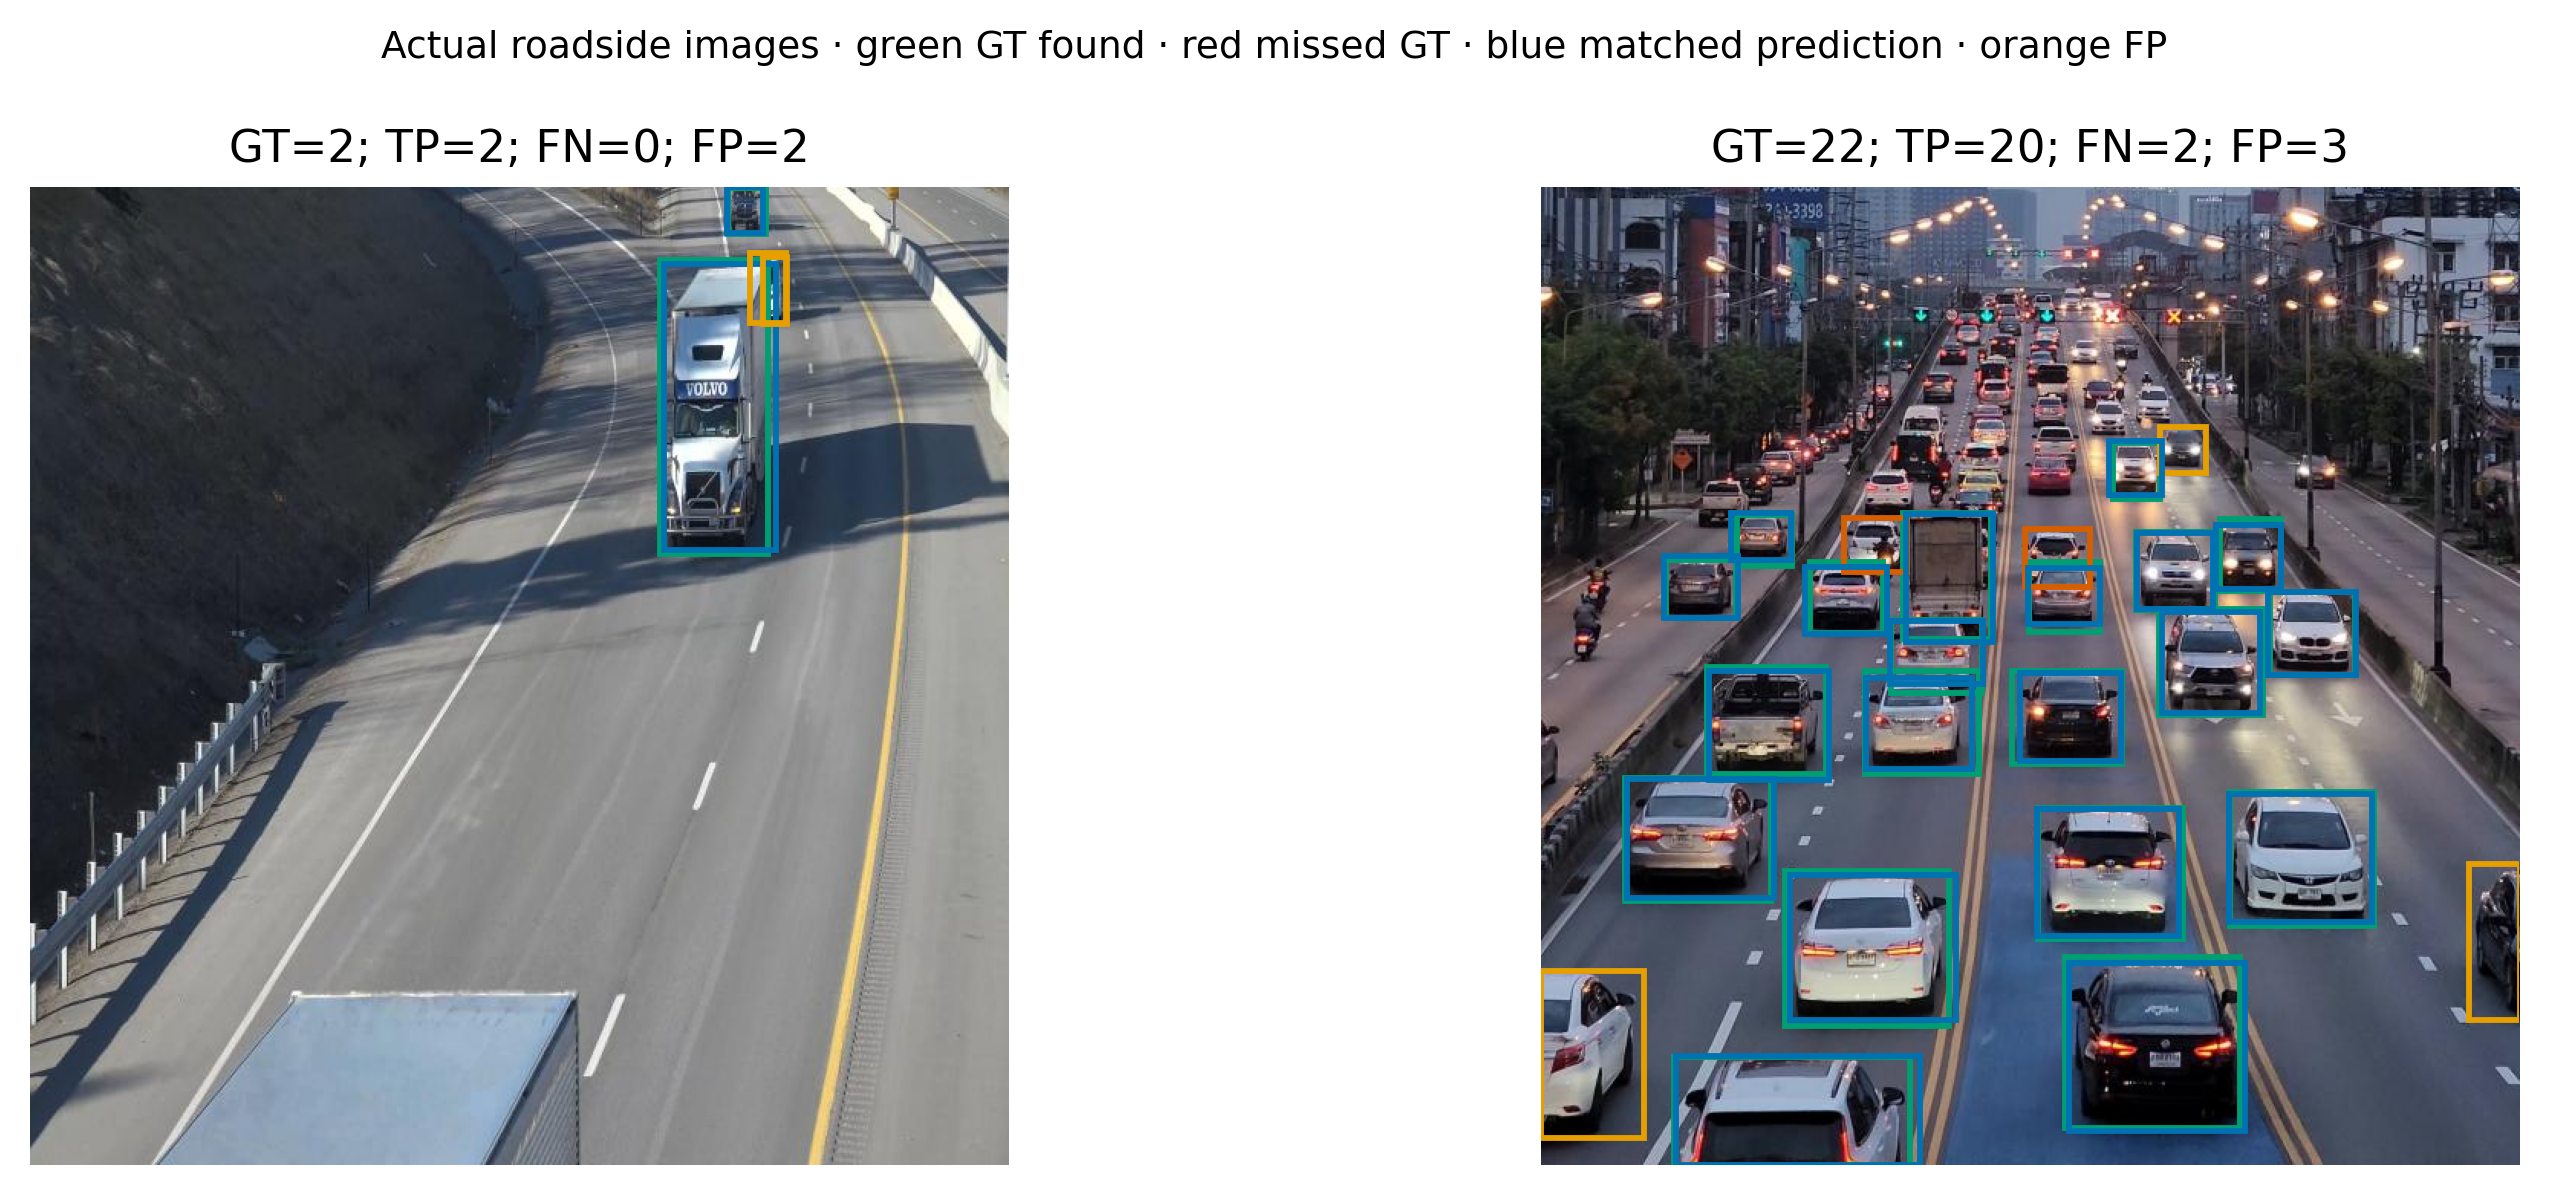

### Figure 2: Actual Per Frame Count

File: figures/actual_per_frame_count.png
Resolution: (2076, 870)


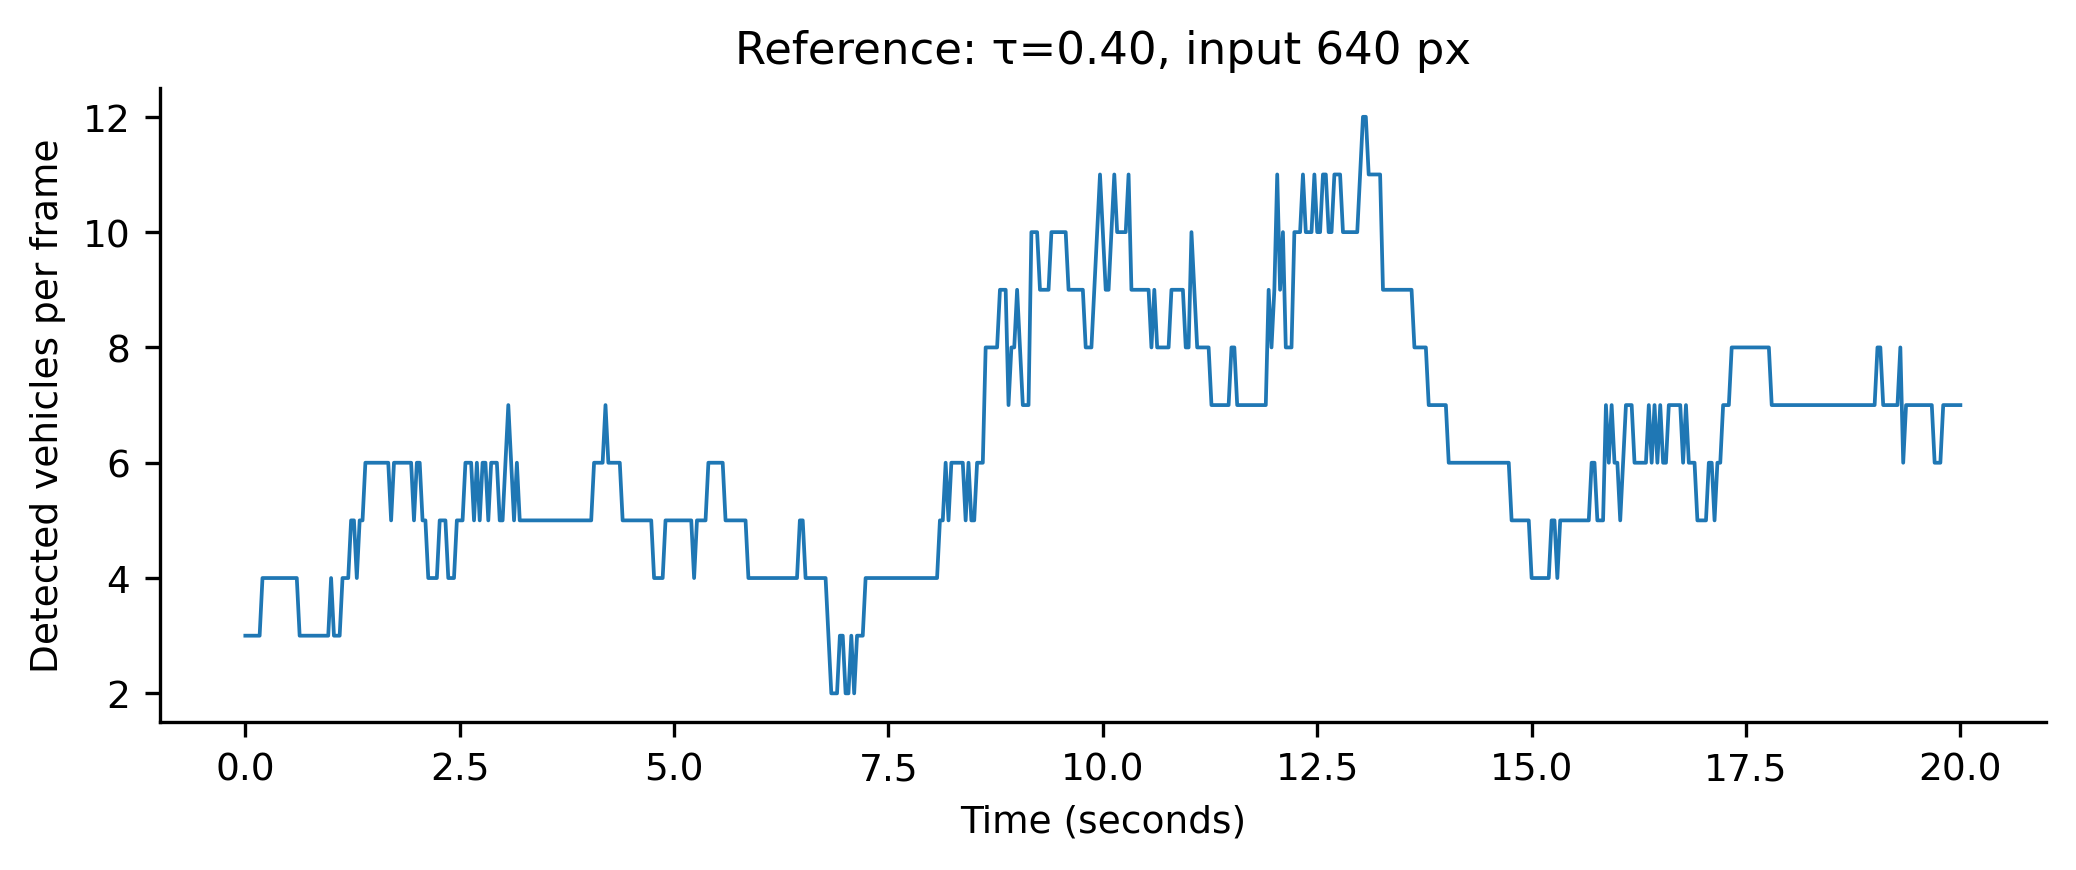

### Figure 3: Quantitative From Saved Results

File: figures/quantitative_from_saved_results.png
Resolution: (3568, 2071)


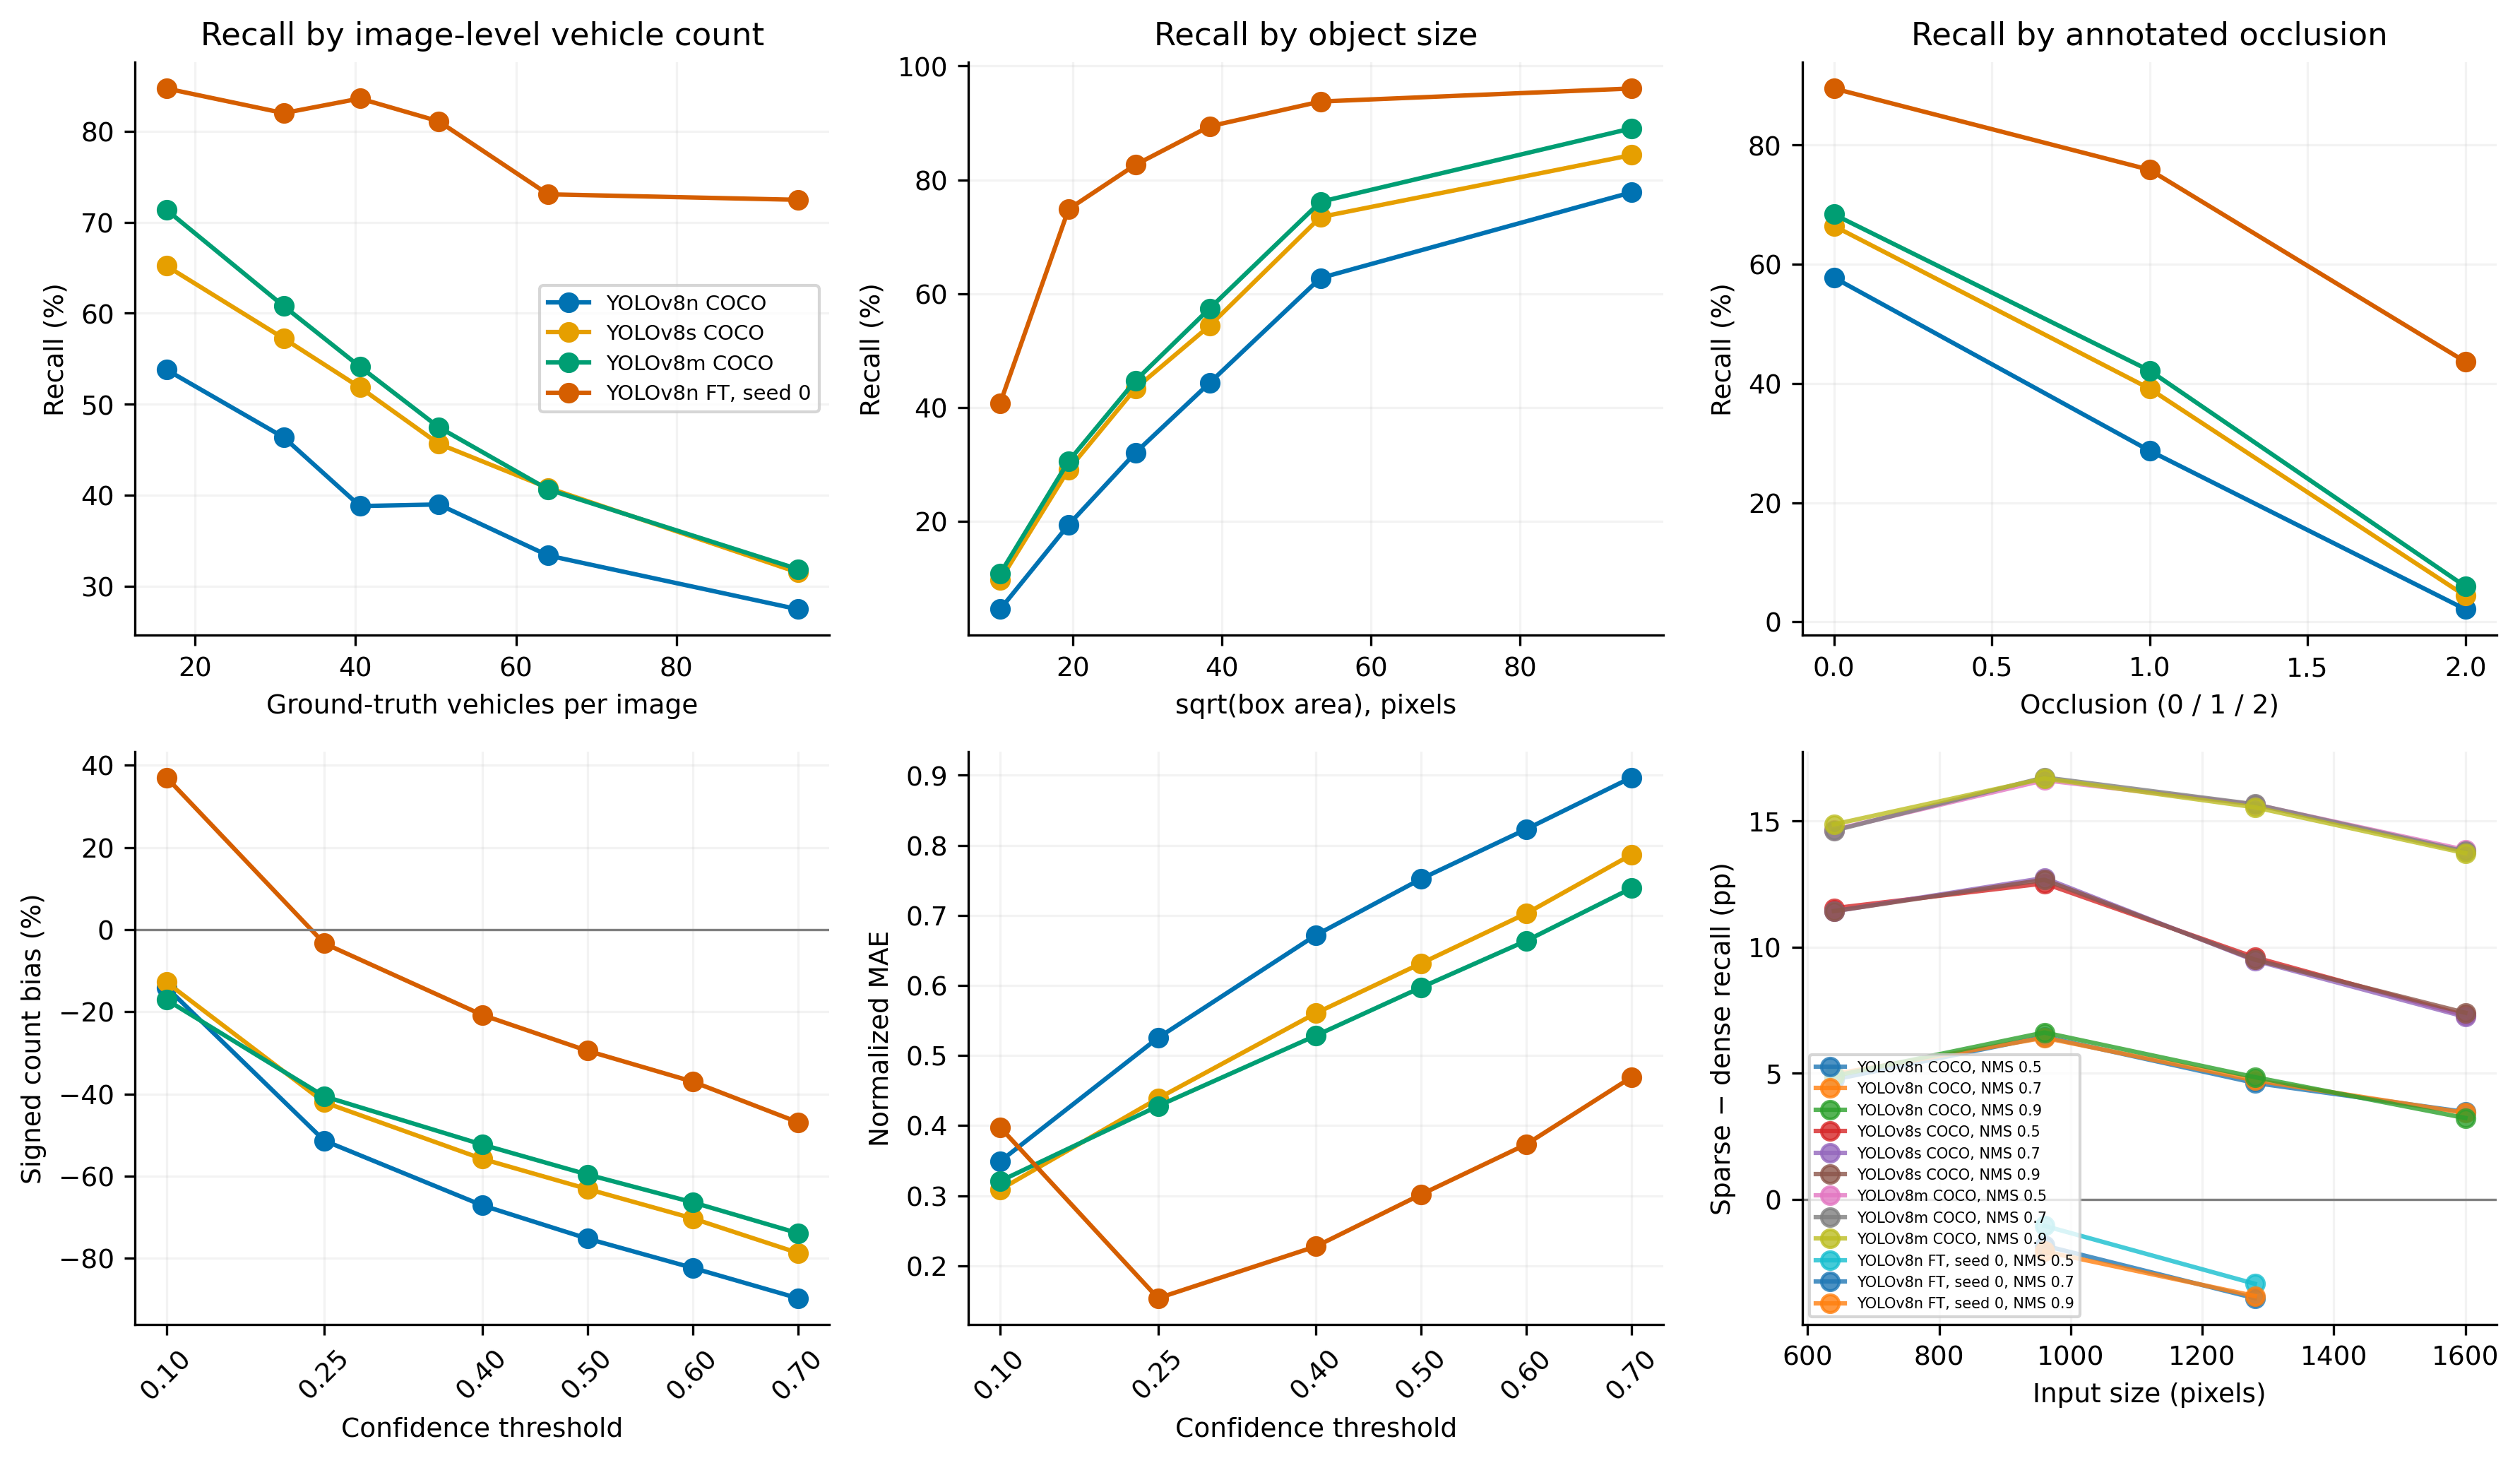

### Figure 4: Replication Forest

File: figures/replication_forest.png
Resolution: (2377, 1233)


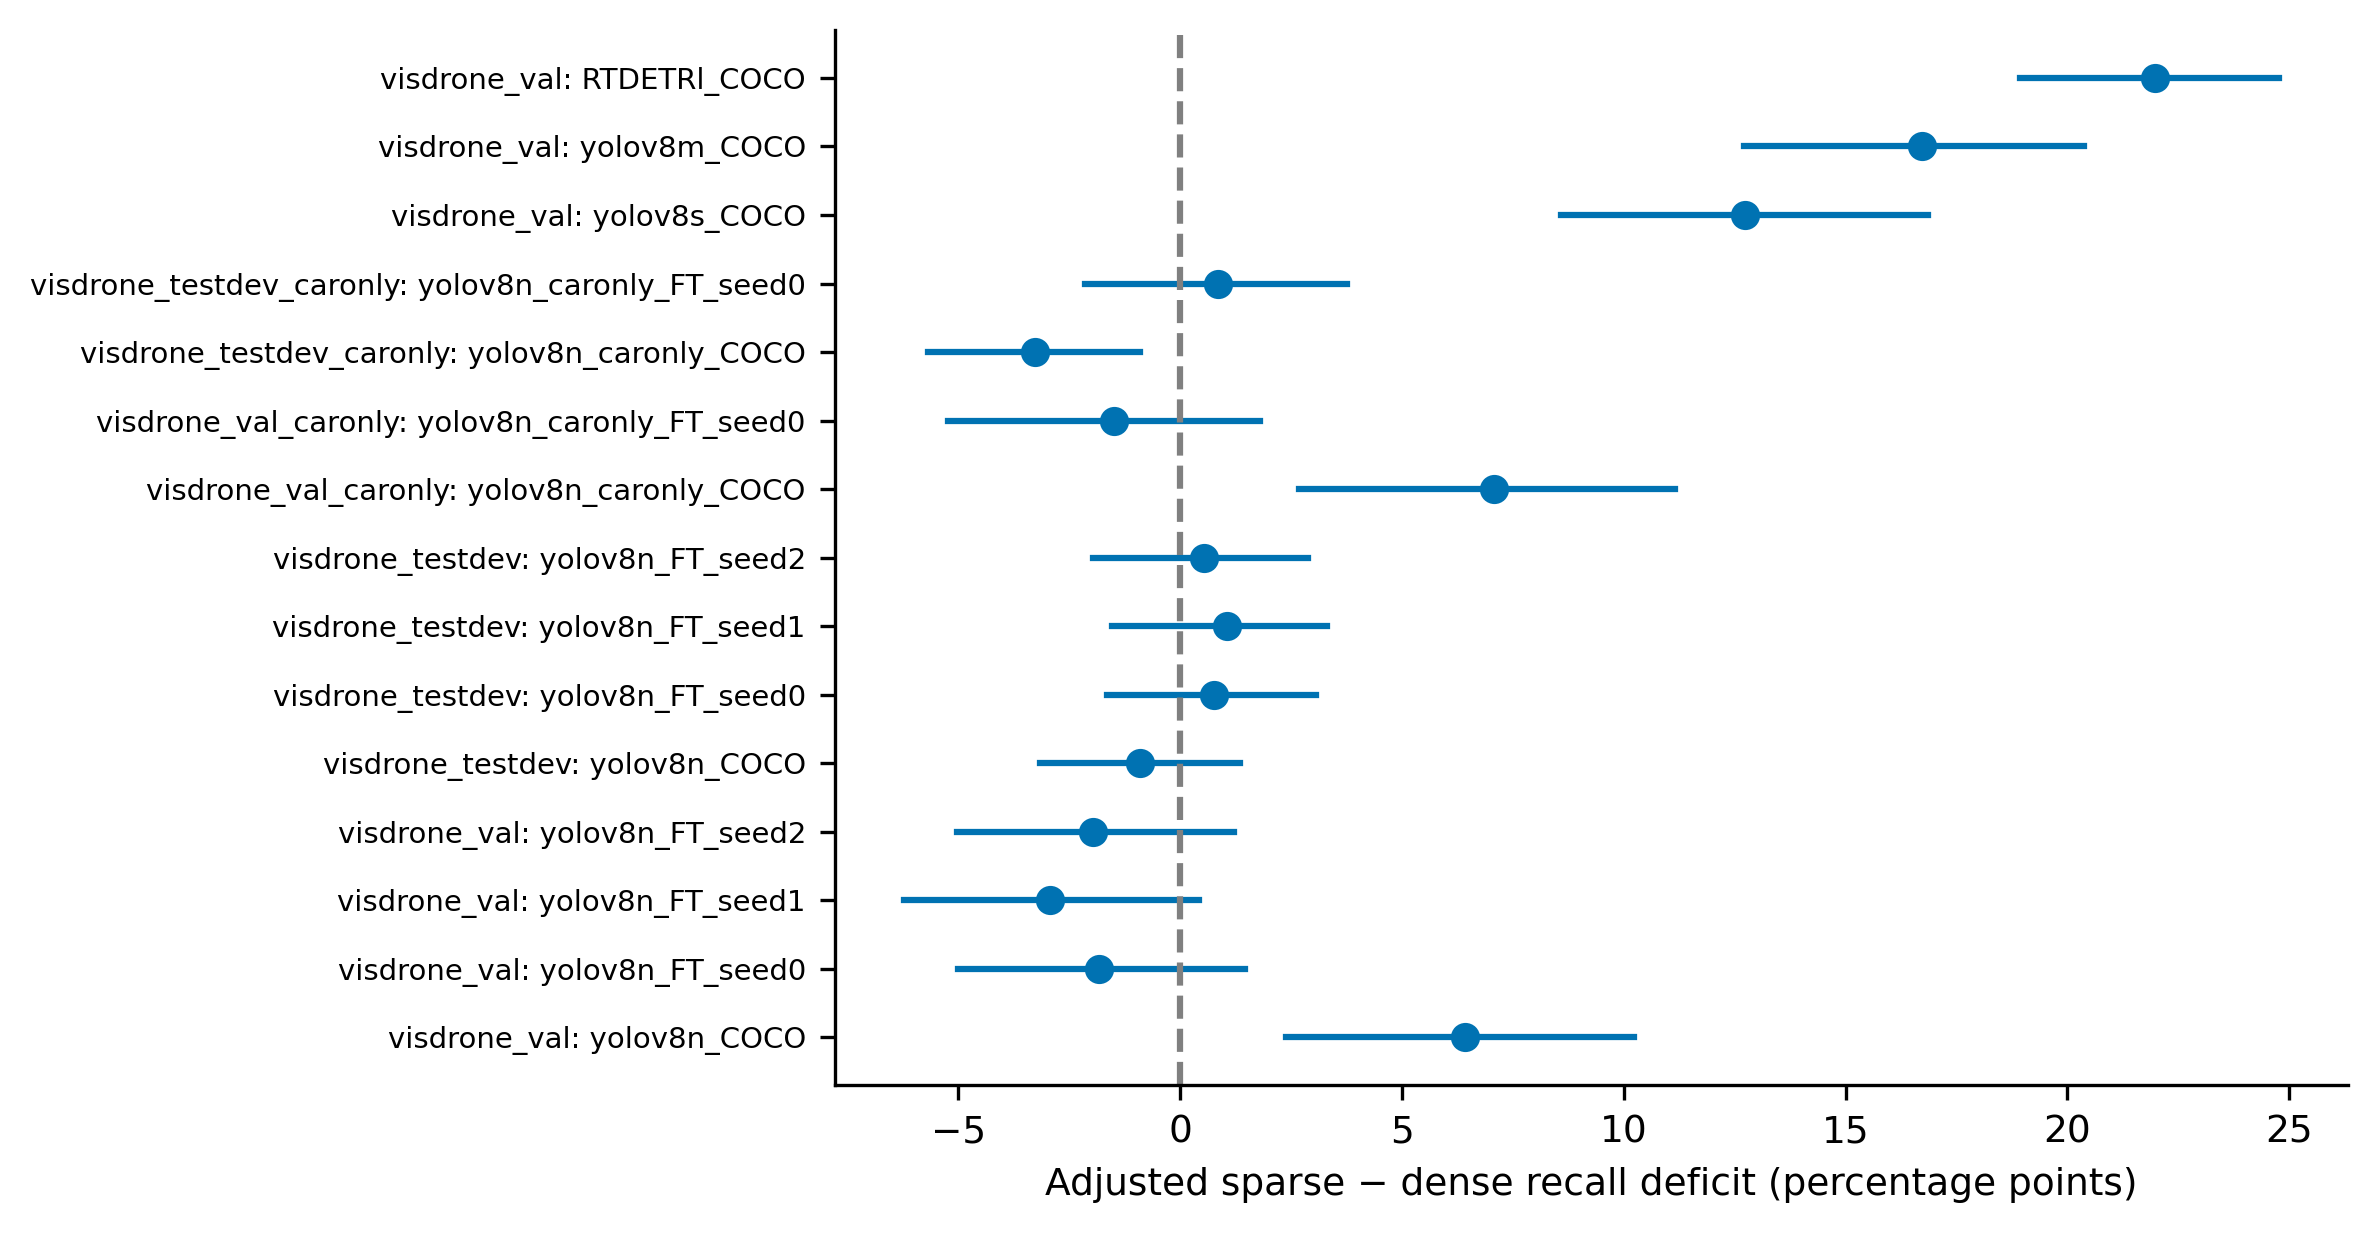

### Figure 5: Video Sensitivity From Saved Results

File: figures/video_sensitivity_from_saved_results.png
Resolution: (3571, 1021)


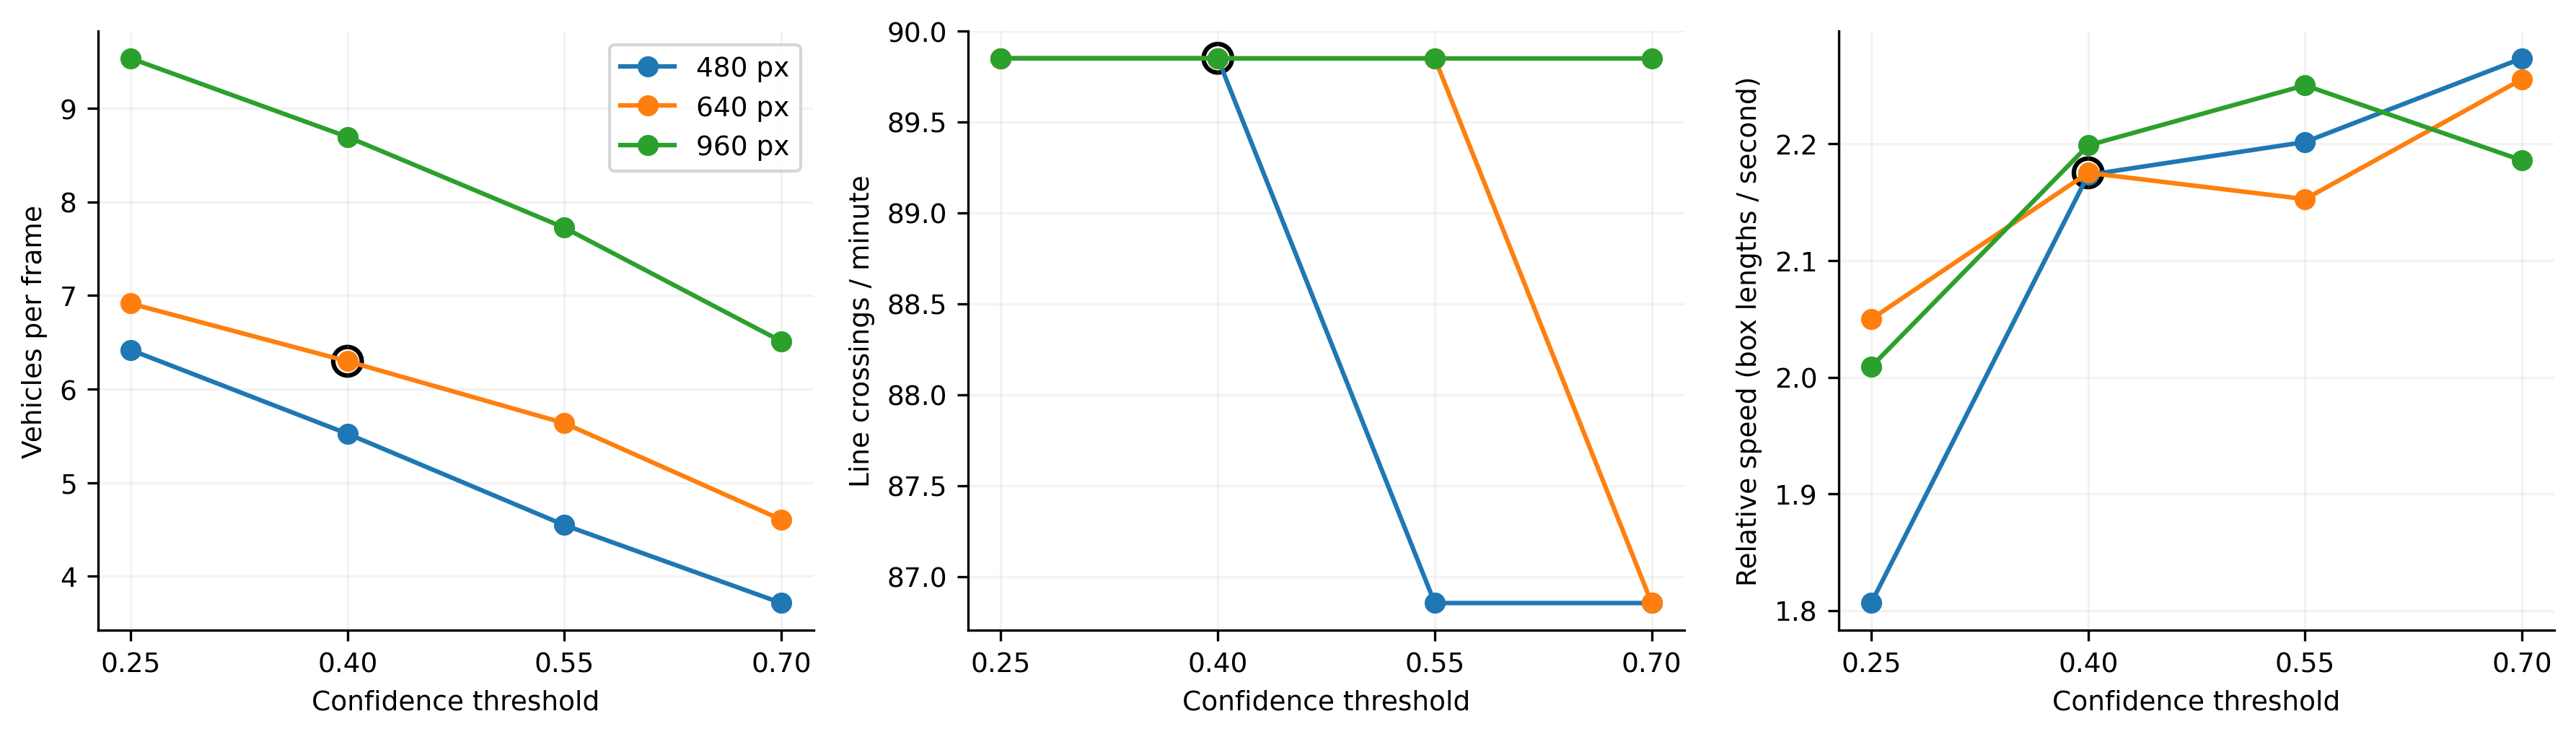

### Figure 6: Within Image Cancellation

File: figures/within_image_cancellation.png
Resolution: (1475, 1171)


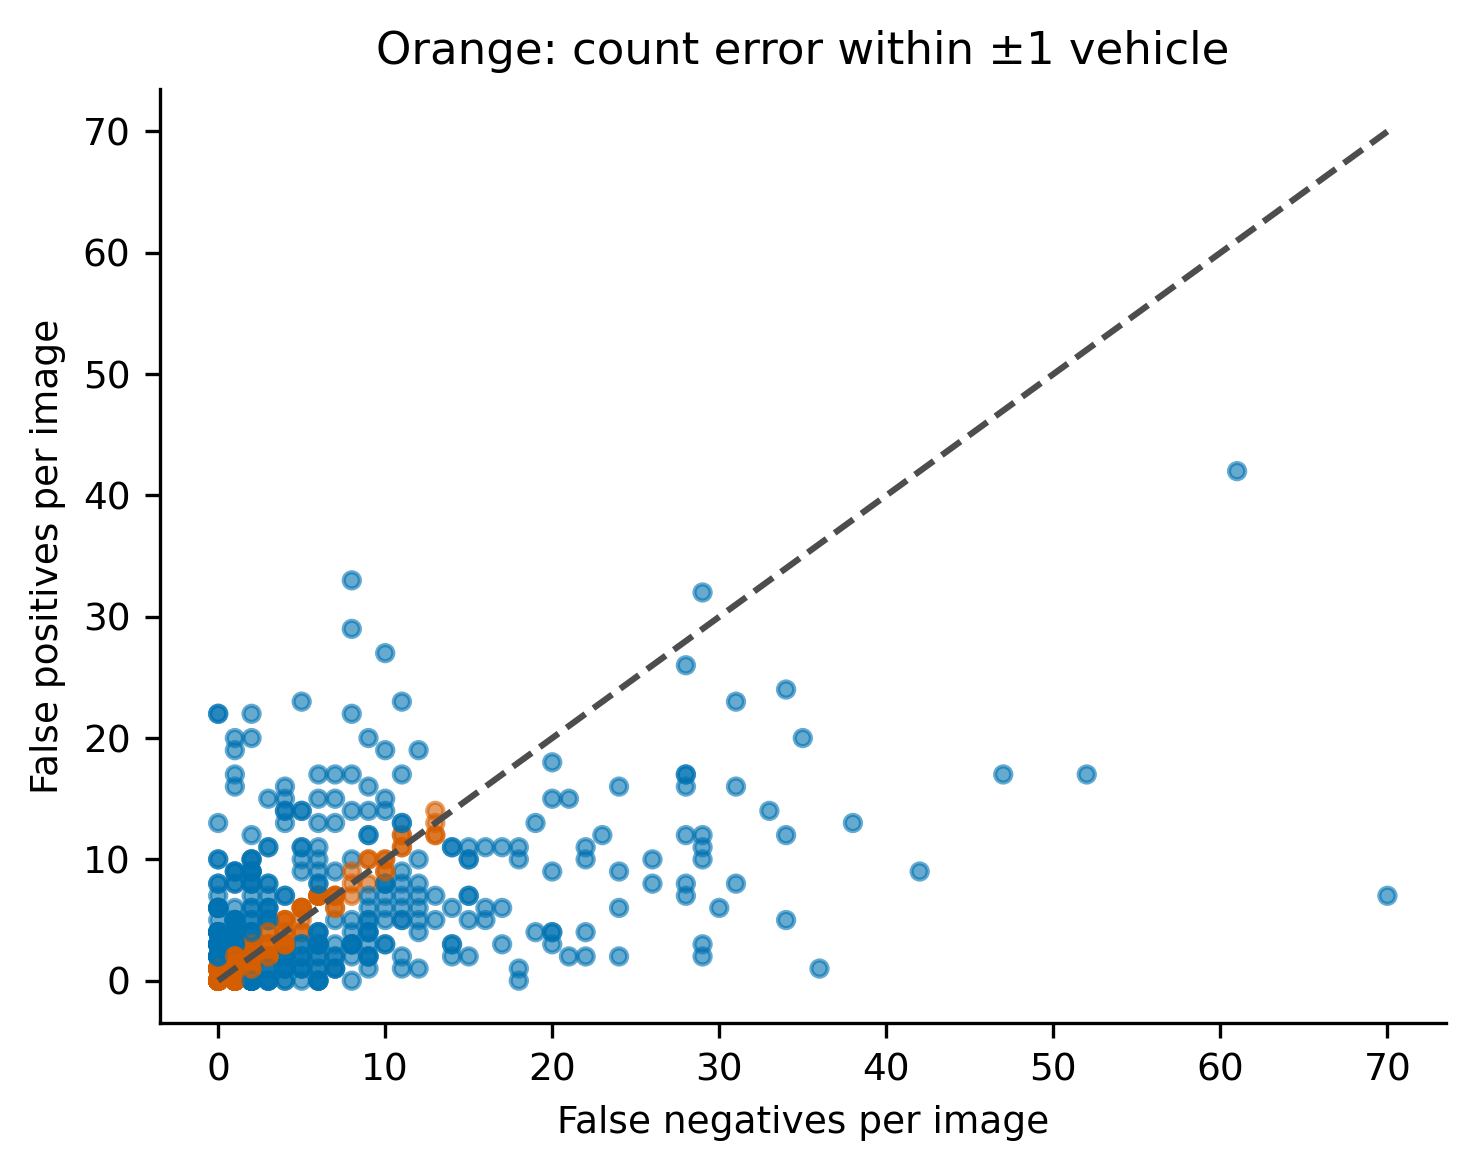

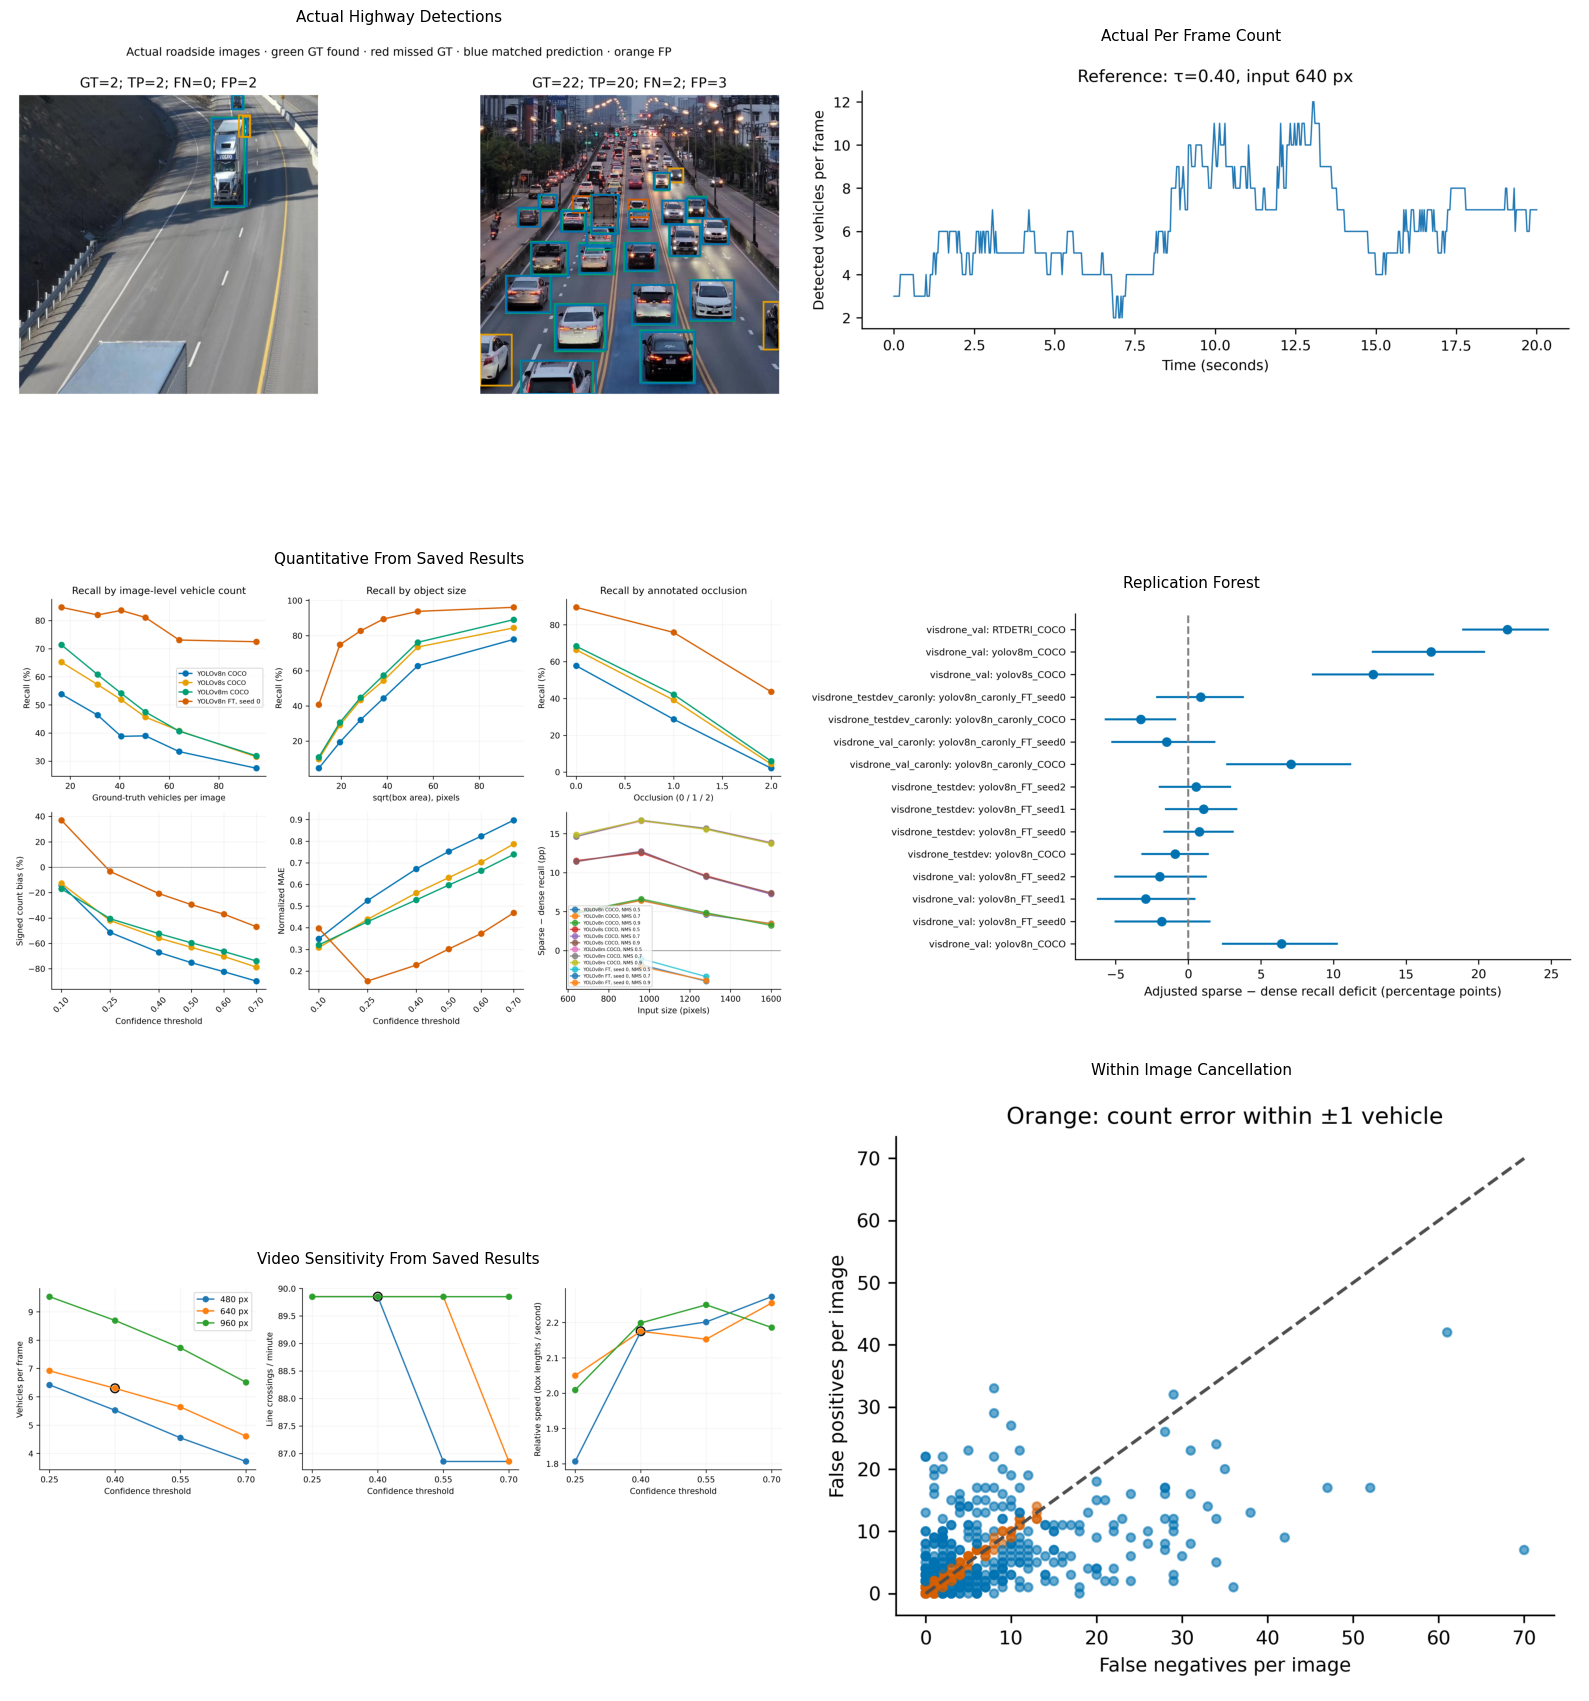


PDF versions:
 - figures/actual_highway_detections.pdf
 - figures/actual_per_frame_count.pdf
 - figures/quantitative_from_saved_results.pdf
 - figures/replication_forest.pdf
 - figures/video_sensitivity_from_saved_results.pdf
 - figures/within_image_cancellation.pdf

FIGURE SHOWCASE COMPLETE
Gallery saved: /kaggle/working/RCWR_CVPR2027_review_r1/figures/RCWR_ALL_FIGURES_GALLERY.png
Original scientific figures remain unchanged.


In [15]:

# ============================================================
# CELL 15 — RCWR CVPR 2027: VISUAL FIGURE GALLERY
# Display all generated scientific figures
# NO retraining | NO inference | NO result modification
# ============================================================

from pathlib import Path
from IPython.display import display, Image, Markdown
from PIL import Image as PILImage
import matplotlib.pyplot as plt
import math

ROOT = Path("/kaggle/working/RCWR_CVPR2027_review_r1")
FIG_DIR = ROOT / "figures"

assert FIG_DIR.is_dir(), f"Figure directory not found: {FIG_DIR}"

# Discover all existing figures automatically
image_exts = {".png", ".jpg", ".jpeg", ".webp"}
figures = sorted(
    p for p in FIG_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in image_exts
)

pdfs = sorted(FIG_DIR.rglob("*.pdf"))

print("=" * 65)
print("RCWR CVPR 2027 — SCIENTIFIC FIGURE GALLERY")
print("=" * 65)
print("Image figures found:", len(figures))
print("PDF figures found:", len(pdfs))
print("Source:", FIG_DIR)

assert figures, "No image figures found."

# PART A — Display each figure separately at high resolution
for i, path in enumerate(figures, 1):
    display(Markdown(
        f"### Figure {i}: {path.stem.replace('_', ' ').title()}"
    ))

    print("File:", path.relative_to(ROOT))

    with PILImage.open(path) as im:
        print("Resolution:", im.size)

    display(Image(filename=str(path), width=1100))

# PART B — Create one overview gallery
cols = 2
rows = math.ceil(len(figures) / cols)

fig, axes = plt.subplots(
    rows, cols,
    figsize=(16, rows * 6),
    squeeze=False
)

for ax in axes.flat:
    ax.axis("off")

for ax, path in zip(axes.flat, figures):
    with PILImage.open(path) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(
        path.stem.replace("_", " ").title(),
        fontsize=11, pad=12
    )
    ax.axis("off")

plt.tight_layout()

gallery_path = FIG_DIR / "RCWR_ALL_FIGURES_GALLERY.png"
plt.savefig(
    gallery_path,
    dpi=180,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()
plt.close(fig)

# PART C — List PDF versions
print("\nPDF versions:")
for p in pdfs:
    print(" -", p.relative_to(ROOT))

print("\n" + "=" * 65)
print("FIGURE SHOWCASE COMPLETE")
print("Gallery saved:", gallery_path)
print("Original scientific figures remain unchanged.")
print("=" * 65)


# Cell 16 — Full experimental evidence inventory

In [16]:

# ============================================================
# CELL 16 — RCWR COMPLETE EVIDENCE INVENTORY
# Metadata only | No training | No inference
# ============================================================

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import pandas as pd
import json

ROOT = Path("/kaggle/working/RCWR_CVPR2027_review_r1")
SMALL = Path("/kaggle/working/RCWR_SCIENTIFIC_RESULTS_SMALL.zip")
OUT = Path("/kaggle/working/RCWR_EVIDENCE_AUDIT.zip")

assert ROOT.is_dir(), "Experiment folder not found"
assert SMALL.exists(), "Scientific ZIP not found"

with ZipFile(SMALL) as z:
    archived = set(z.namelist())

records = []

for p in sorted(ROOT.rglob("*")):
    if not p.is_file():
        continue

    relative = p.relative_to(ROOT).as_posix()
    size_mb = p.stat().st_size / (1024 ** 2)

    records.append({
        "relative_path": relative,
        "category": relative.split("/")[0],
        "extension": p.suffix.lower(),
        "size_mb": round(size_mb, 4),
        "included_in_small_zip": relative in archived
    })

df = pd.DataFrame(records)

print("=" * 65)
print("RCWR — COMPLETE EVIDENCE AUDIT")
print("=" * 65)

print("Files found:", len(df))
print("Already in small ZIP:",
      int(df["included_in_small_zip"].sum()))
print("Not in small ZIP:",
      int((~df["included_in_small_zip"]).sum()))

print("\nLargest files not in small ZIP:")
missing = df[~df["included_in_small_zip"]]
print(
    missing.nlargest(20, "size_mb").to_string(index=False)
)

summary = {
    "total_files": len(df),
    "in_small_zip": int(df["included_in_small_zip"].sum()),
    "not_in_small_zip": len(missing),
    "total_size_mb": round(df["size_mb"].sum(), 2),
    "omitted_size_mb": round(missing["size_mb"].sum(), 2),
    "note": "Inventory only; no experimental data modified"
}

with ZipFile(OUT, "w", ZIP_DEFLATED) as z:
    z.writestr(
        "EVIDENCE_INVENTORY.csv",
        df.to_csv(index=False)
    )
    z.writestr(
        "EVIDENCE_SUMMARY.json",
        json.dumps(summary, indent=2)
    )

print("\nAUDIT COMPLETE")
print("Archive:", OUT.name)
print("Archive size (MB):",
      round(OUT.stat().st_size / 1024**2, 3))
print("Original experimental data unchanged.")


RCWR — COMPLETE EVIDENCE AUDIT
Files found: 81916
Already in small ZIP: 585
Not in small ZIP: 81331

Largest files not in small ZIP:
                                         relative_path  category extension   size_mb  included_in_small_zip
                  downloads/VisDrone2019-DET-train.zip downloads      .zip 1478.0765                  False
               downloads/VisDrone2019-DET-test-dev.zip downloads      .zip  296.8328                  False
                    downloads/VisDrone2019-DET-val.zip downloads      .zip   77.8569                  False
downloads/top-view-vehicle-detection-image-dataset.zip downloads      .zip   45.6200                  False
  training/visdrone_car_seed0/weights/recovery_last.pt  training       .pt   17.6490                  False
      training/visdrone_seed0/weights/recovery_last.pt  training       .pt   17.6490                  False
      training/visdrone_seed1/weights/recovery_last.pt  training       .pt   17.6490                  False
   

## Review-response map and interpretation rules

| Review issue | Implemented response / remaining limitation |
|---|---|
| 1, 2, 28–38 | Manuscript/administrative work deferred to Find → Replace. LLM statement is mandatory; disclose actual ChatGPT help with code, analysis design, editing and any AI-generated figures used. Do not use a “no AI” statement. Source claims, formatting and dual submission need author review. |
| 4–12 | Numerical plots/tables now read the same saved results; model names and thresholds are generated from identifiers. Per-frame means are asserted against video tables. Final paper layout remains deferred. |
| 13 | Highway described as roadside oblique view; dataset's proper title can stay unchanged. |
| 14 | New checkpoint selection uses internal validation from original training only. Exact cross-split duplicate hashes excluded from training. Highway dHash matches are candidates, not proof of leakage or independence. Previously inspected validation is not newly pristine. |
| 15–18, 20 | Controlled replication, three seeds, car-only training control; adjusted association language. No causal claims, no assumption that occlusion is merely a confound, no universal absence of density effects. |
| 19 | Centered-bootstrap approximate TOST and dual 90% basic interval, margins ±1/2/3/5 pp. **Exploratory:** margin choice lacks an independent application-specific SESOI justification. |
| 21 | Fixed original pooled weights, no bootstrap-dependent stratum deletion, full stratum counts/exclusions, alternate size bands and minimum counts. Invalid replicates are counted; >1% invalid suppresses inference. |
| 22 | Neighbor counts and clustered logistic models; image count explicitly differs from physical traffic density. |
| 23 | Within-image hidden errors = 2 min(FP,FN); across-image cancellation = sum(abs(FP−FN)) − abs(sum(FP−FN)); both exported. |
| 24 | GAME at every level, absolute error and ratio; uniform relocation is an illustrative spatial null, not a new metric or realistic traffic model. |
| 25 | Paired identical bootstrap draws for setting differences; no comparison against an unrelated CI half-width. |
| 26 | One documented ByteTrack implementation, no fallback, raw counts and timestamps, optional manual annotations. Single-clip study remains illustrative; the code cannot manufacture independent videos or annotations. |
| 27 | Image/label hashes, split IDs, environment, seeds, training args, frozen checkpoint hashes, raw prediction caches, bootstrap draws, synthetic data/results, CSV-to-figure provenance. |

**Units:** recall curves use percent; recall differences and CIs use **percentage points** (`_pp`); signed bias uses percent; nMAE and GAME ratios are dimensionless. These are different quantities, not interchangeable units.

**Seed inference:** seed-specific effects and between-seed spread are reported. The CI for their equal-weight average is conditional on the observed checkpoints; it does not estimate uncertainty over arbitrary training seeds. Never choose the best seed using evaluation results. Seed 0 is the fixed illustrative checkpoint.

**Protocol changes relative to the old notebook:** fixed stratification weights; all matched inference at 960 pixels; class-agnostic NMS applied consistently; AdamW explicitly fixed; batch 8; internal-validation checkpoint selection; additional seeds/control. These are new runs and need new paper values. Truncation is retained; ignored-region center filtering is a documented custom diagnostic protocol, not official VisDrone AP evaluation. Single-class training does not mask ignored regions, and this remains a limitation.

**Reference guidance checked:** https://cvpr.thecvf.com/Conferences/2027/AuthorGuidelines
The main-paper deadline and supplementary deadline are separate. This notebook does not assess your registration, author eligibility, submission metadata or overlapping submissions.
